In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('merged_df_raw.csv')
df.head(5)

,REGION,SETTLEMENTDATE,TOTALDEMAND,RRP,PERIODTYPE,station_number,year_local,month_local,day_local,hour_local,...,max_gust_kmh,max_gust_quality,mslp_hpa,mslp_quality,station_level_pressure_hpa,station_level_pressure_quality,aws_flag,station_name,latitude,longitude
0,NSW1,2000-09-01 00:30:00,8117.23667,36.72,TRADE,66062.0,2000.0,9.0,1.0,1.0,...,NaN,NaN,1011.3,N,1006.5,N,1.0,SYDNEY (OBSERVATORY HILL),-33.8607,151.205
1,NSW1,2000-09-01 01:00:00,7799.70000,32.92,TRADE,66062.0,2000.0,9.0,1.0,2.0,...,NaN,NaN,1011.1,N,1006.3,N,1.0,SYDNEY (OBSERVATORY HILL),-33.8607,151.205
2,NSW1,2000-09-01 01:30:00,7453.99000,27.84,TRADE,66062.0,2000.0,9.0,1.0,2.0,...,NaN,NaN,1011.3,N,1006.5,N,1.0,SYDNEY (OBSERVATORY HILL),-33.8607,151.205
3,NSW1,2000-09-01 02:00:00,7095.55333,30.62,TRADE,66062.0,2000.0,9.0,1.0,3.0,...,NaN,NaN,1011.3,N,1006.5,N,1.0,SYDNEY (OBSERVATORY HILL),-33.8607,151.205
4,NSW1,2000-09-01 02:30:00,6786.22167,33.53,TRADE,66062.0,2000.0,9.0,1.0,3.0,...,NaN,NaN,1011.2,N,1006.4,N,1.0,SYDNEY (OBSERVATORY HILL),-33.8607,151.205


In [3]:
# Convert settlement date to datetime
df["SETTLEMENTDATE"] = pd.to_datetime(df["SETTLEMENTDATE"])

# Sort chronologically
df = df.sort_values(["REGION", "SETTLEMENTDATE"]).reset_index(drop=True)

# the notes recommend treating RH values slightly above 100% as 100%.
df["relative_humidity_pct"] = (
    df["relative_humidity_pct"].clip(upper=100)
)

In [4]:

df = df.drop(columns=[
    "PERIODTYPE",
    "year_local",
    "month_local",
    "day_local",
    "hour_local",
    "minute_local",
    "year_std",
    "month_std",
    "day_std",
    "hour_std",
    "minute_std"
])

#reformat the time so that it is tidier
df["year"] = df["SETTLEMENTDATE"].dt.year
df["month"] = df["SETTLEMENTDATE"].dt.month
df["day"] = df["SETTLEMENTDATE"].dt.day
df["hour"] = df["SETTLEMENTDATE"].dt.hour
df["date"] = df["SETTLEMENTDATE"].dt.date


In [5]:
#gets rid of the 2020 rows isnce they skew the data
df= df.drop(df.loc[df['year'] == 2020].index)

In [6]:
df.columns

Index(['REGION', 'SETTLEMENTDATE', 'TOTALDEMAND', 'RRP', 'station_number',
       'precipitation_9am_mm', 'precipitation_quality', 'air_temperature_c',
       'air_temperature_quality', 'wet_bulb_temp_c', 'wet_bulb_quality',
       'dew_point_temp_c', 'dew_point_quality', 'relative_humidity_pct',
       'relative_humidity_quality', 'wind_speed_kmh', 'wind_speed_quality',
       'wind_direction_deg', 'wind_direction_quality', 'max_gust_kmh',
       'max_gust_quality', 'mslp_hpa', 'mslp_quality',
       'station_level_pressure_hpa', 'station_level_pressure_quality',
       'aws_flag', 'station_name', 'latitude', 'longitude', 'year', 'month',
       'day', 'hour', 'date'],
      dtype='object')

In [7]:
df["season"] = df["month"].map({
    12: "Summer",
    1: "Summer",
    2: "Summer",
    3: "Autumn",
    4: "Autumn",
    5: "Autumn",
    6: "Winter",
    7: "Winter",
    8: "Winter",
    9: "Spring",
    10: "Spring",
    11: "Spring"
})

In [8]:
dfdaily = (
    df.groupby(["REGION", "date", "year"])
      .agg(
          demand_mean=("TOTALDEMAND", "mean"),
          demand_max=("TOTALDEMAND", "max"),
          demand_min=("TOTALDEMAND", "min"),
          temp_mean=("air_temperature_c", "mean"),
          temp_max=("air_temperature_c", "max"),
          temp_min=("air_temperature_c", "min"),
          humidity_mean=("relative_humidity_pct", "mean"),
          precipitation=("precipitation_9am_mm", "max")
      )
      .reset_index()
)

dfdaily.head(5)

,REGION,date,year,demand_mean,demand_max,demand_min,temp_mean,temp_max,temp_min,humidity_mean,precipitation
0,NSW1,2000-01-01,2000,5720.094291,6763.57000,4650.29167,18.155319,20.8,14.8,66.382979,0.2
1,NSW1,2000-01-02,2000,5918.343333,6650.00333,4683.24667,17.979167,19.5,16.4,85.625000,18.8
2,NSW1,2000-01-03,2000,6234.452951,6936.19500,4820.81333,20.389583,23.3,16.4,76.770833,19.6
3,NSW1,2000-01-04,2000,7196.844653,8286.73500,5145.15000,24.879167,30.2,19.2,56.770833,0.2
4,NSW1,2000-01-05,2000,7076.017153,7932.49167,5328.70000,20.785417,24.9,17.3,46.354167,0.0


In [9]:
dfmonthly = (
    df.groupby(["REGION", "month", "year"])
      .agg(
          demand_mean=("TOTALDEMAND", "mean"),
          demand_max=("TOTALDEMAND", "max"),
          demand_min=("TOTALDEMAND", "min"),
          temp_mean=("air_temperature_c", "mean"),
          temp_max=("air_temperature_c", "max"),
          temp_min=("air_temperature_c", "min"),
          humidity_mean=("relative_humidity_pct", "mean"),
          precipitation=("precipitation_9am_mm", "max")
      )
      .reset_index()
)

dfmonthly["month_cumulative"] = dfmonthly['month'] + (dfmonthly['year'] - 2000)*12
dfmonthly.head(5)

,REGION,month,year,demand_mean,demand_max,demand_min,temp_mean,temp_max,temp_min,humidity_mean,precipitation,month_cumulative
0,NSW1,1,2000,7153.476519,10404.95167,4650.29167,20.904720,34.7,14.8,68.898854,19.6,1
1,NSW1,1,2001,7892.775532,11547.42833,4973.09833,23.415048,31.6,16.5,73.932969,110.4,13
2,NSW1,1,2002,7835.624325,10981.60500,5322.12167,22.843660,36.8,16.0,67.630569,26.6,25
3,NSW1,1,2003,8081.132294,12331.45167,5344.19167,22.879583,38.6,16.2,67.763889,3.6,37
4,NSW1,1,2004,8265.071207,11690.89833,5730.18000,23.112307,32.8,16.5,71.354405,20.8,49


In [10]:
dfannual = (
    dfdaily.groupby(["REGION", "year"])
         .agg(
             mean_demand=("demand_mean", "mean"),
             max_demand=("demand_max", "max"),
             mean_temp=("temp_mean", "mean"),
             max_temp=("temp_max", "max"),
             min_temp=("temp_min", "min")
         )
         .reset_index()
)
dfannual.head(5)

,REGION,year,mean_demand,max_demand,mean_temp,max_temp,min_temp
0,NSW1,2000,7841.175976,11822.15000,18.021842,38.1,5.7
1,NSW1,2001,7958.504637,11712.76833,18.197621,35.8,5.9
2,NSW1,2002,8140.782544,12074.24000,18.202859,37.5,4.3
3,NSW1,2003,8247.651927,12331.45167,17.961880,38.6,4.9
4,NSW1,2004,8452.372520,12838.14167,18.290754,39.1,6.0


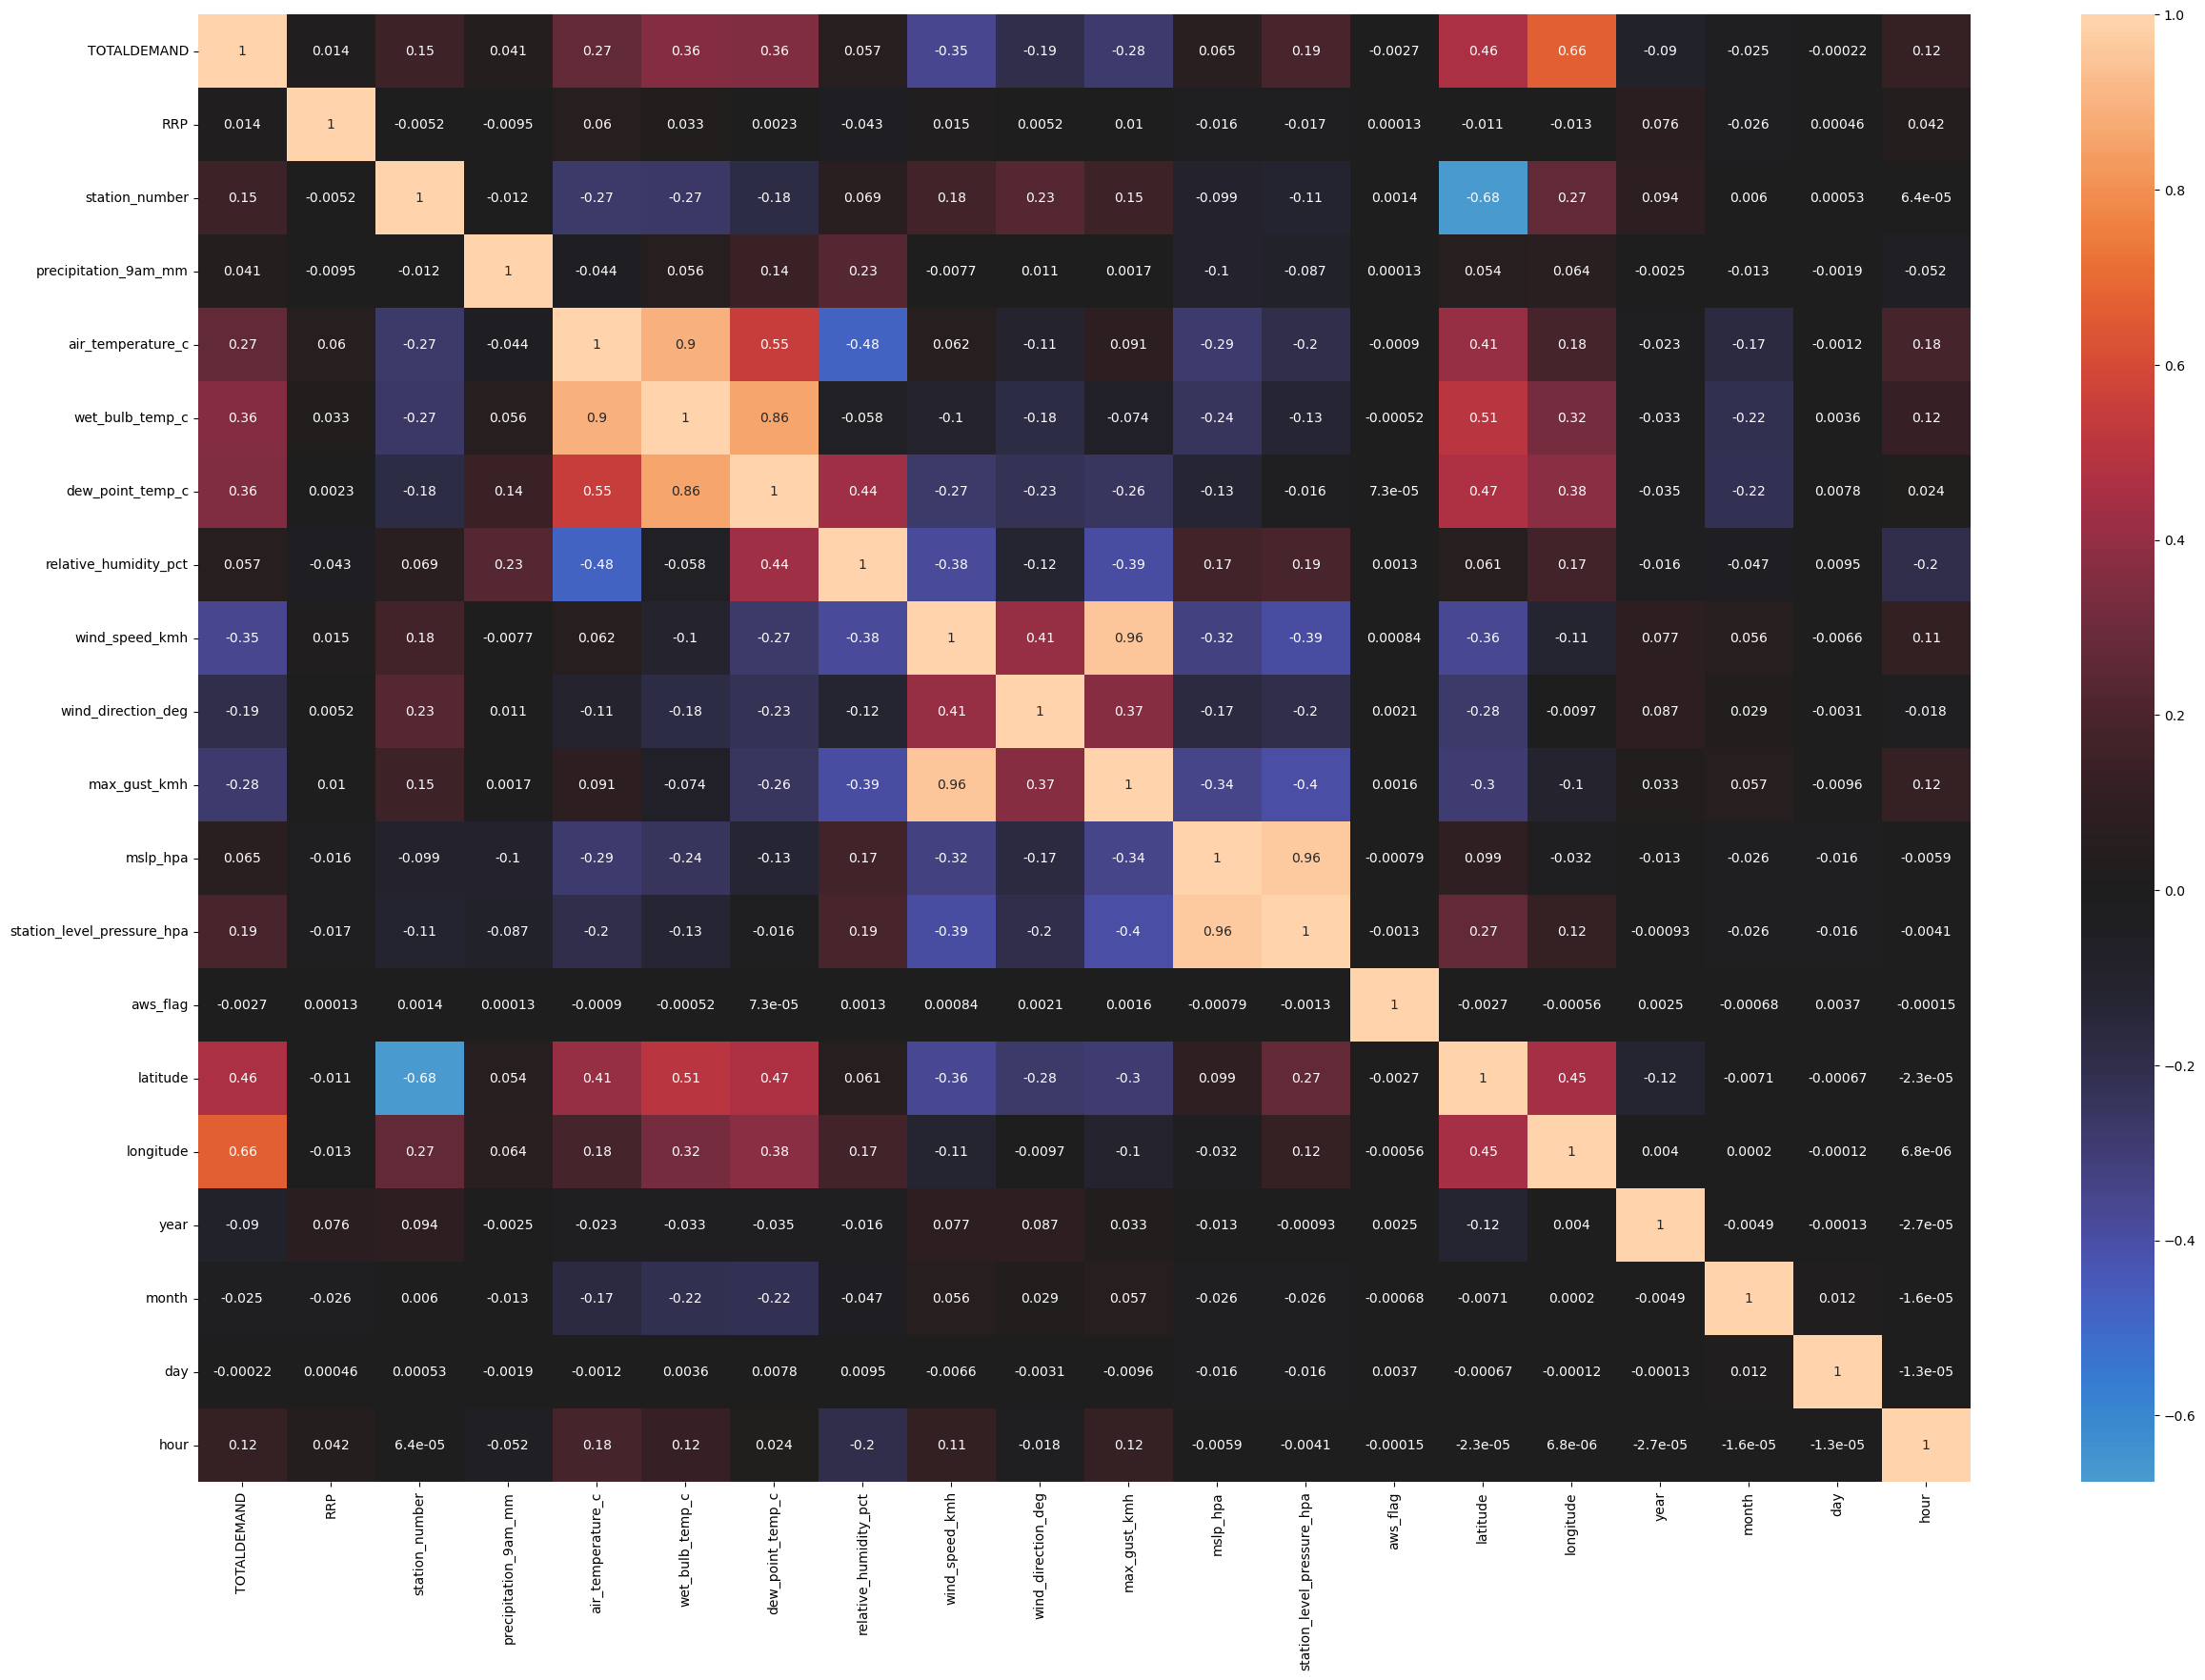

In [11]:
corr = df.corr(numeric_only=True)
plt.figure(figsize=(30, 20))
sns.heatmap(corr, annot=True, center=0)
plt.show()

In [12]:
#plt.figure(figsize=(12, 6))
#sns.pairplot(data= df)

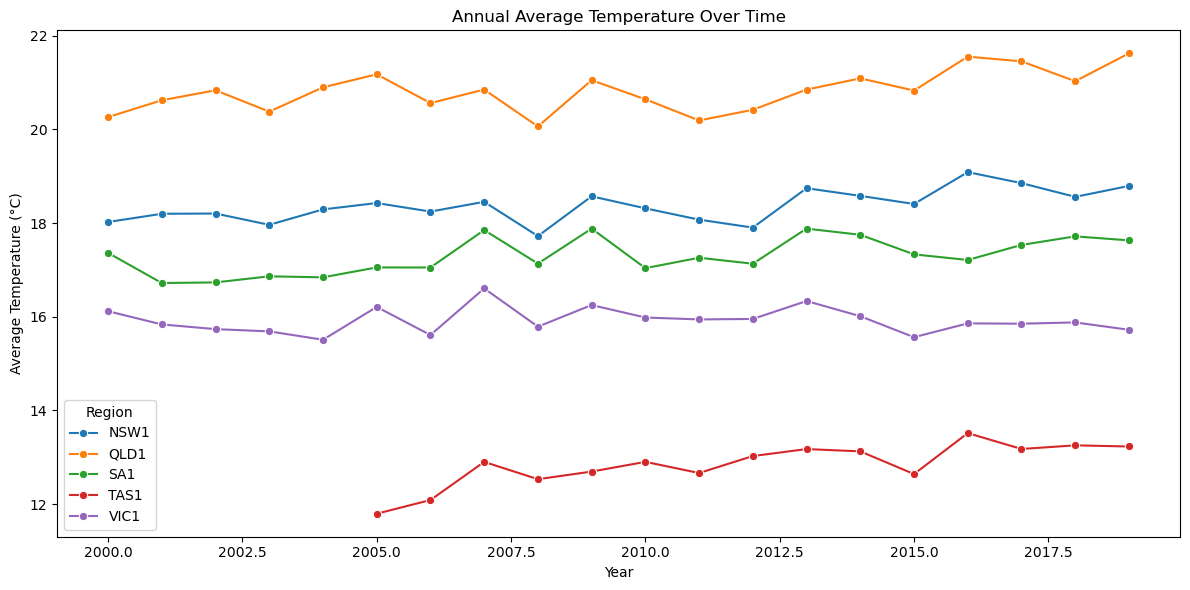

In [13]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=dfannual,
    x="year",
    y="mean_temp",
    hue="REGION",
    marker="o"
)

plt.xlabel("Year")
plt.ylabel("Average Temperature (°C)")
plt.title("Annual Average Temperature Over Time")
plt.legend(title="Region")
plt.tight_layout()
plt.show()

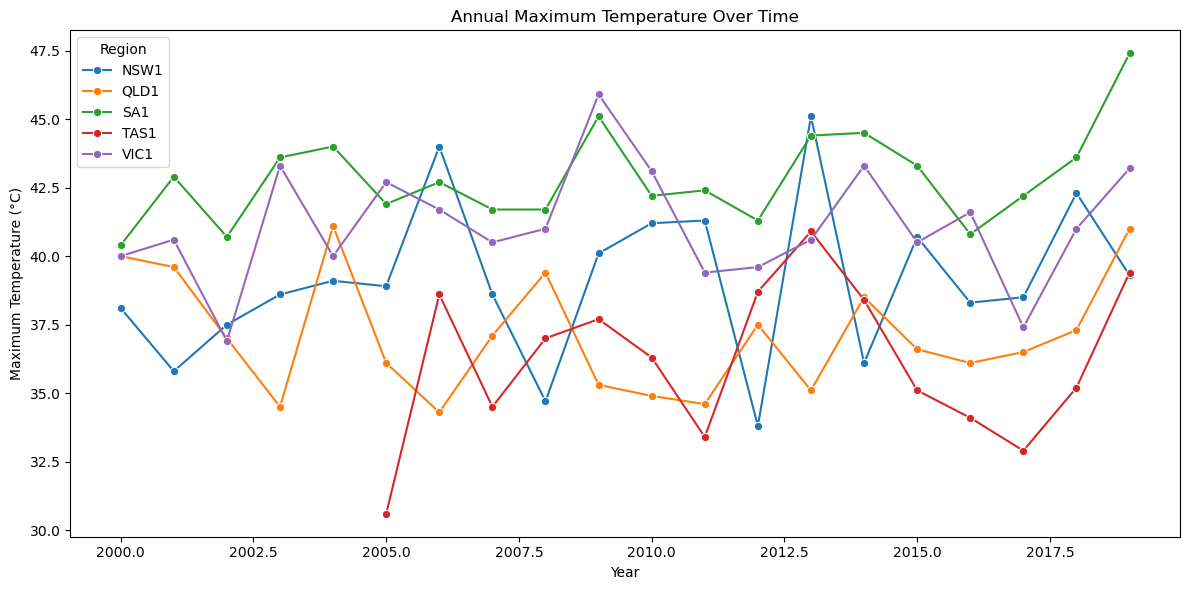

In [14]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=dfannual,
    x="year",
    y="max_temp",
    hue="REGION",
    marker="o"
)

plt.xlabel("Year")
plt.ylabel("Maximum Temperature (°C)")
plt.title("Annual Maximum Temperature Over Time")
plt.legend(title="Region")
plt.tight_layout()
plt.show()

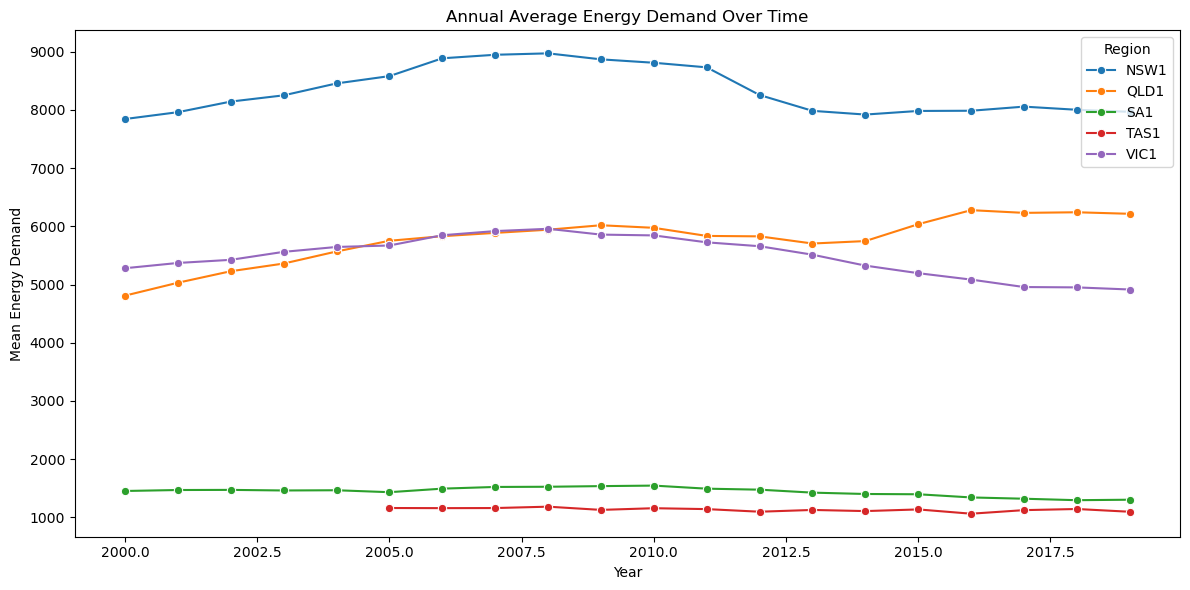

In [15]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=dfannual,
    x="year",
    y="mean_demand",
    hue="REGION",
    marker="o"
)

plt.xlabel("Year")
plt.ylabel("Mean Energy Demand")
plt.title("Annual Average Energy Demand Over Time")
plt.legend(title="Region")
plt.tight_layout()
plt.show()

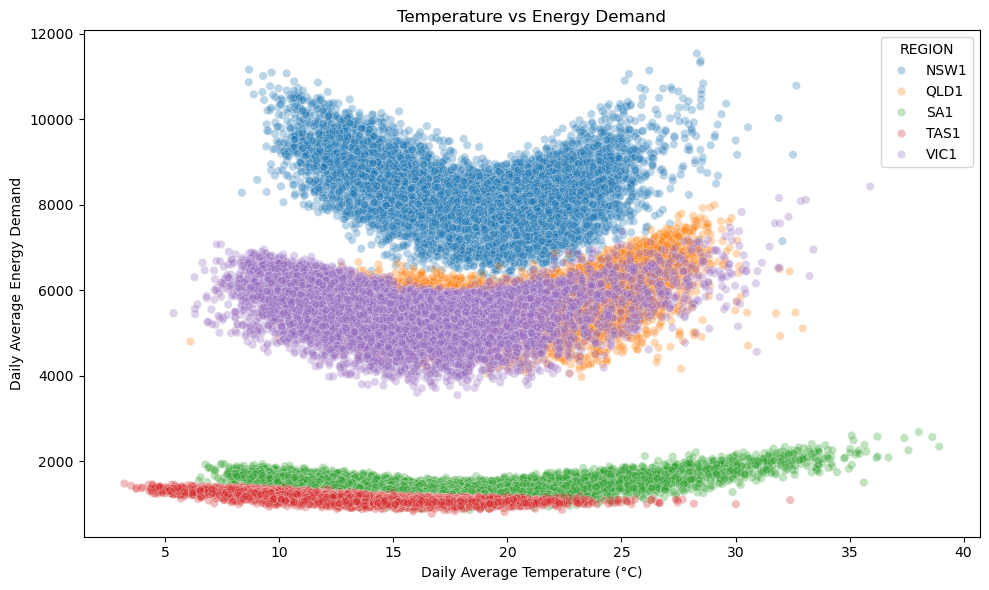

In [16]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=dfdaily,
    x="temp_mean",
    y="demand_mean",
    hue="REGION",
    alpha=0.3
)

plt.xlabel("Daily Average Temperature (°C)")
plt.ylabel("Daily Average Energy Demand")
plt.title("Temperature vs Energy Demand")
plt.tight_layout()
plt.show()

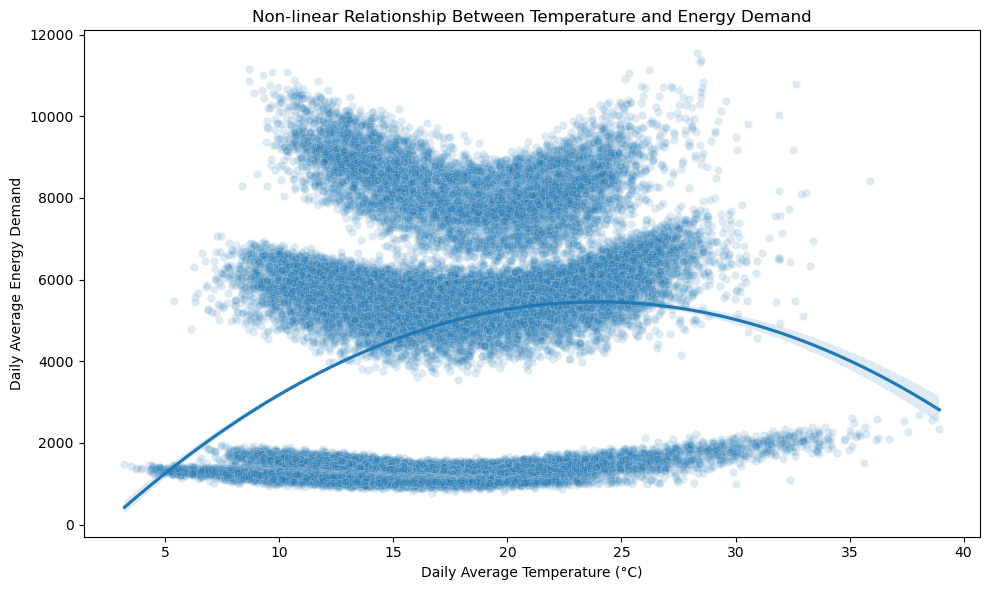

In [17]:
plot_data = dfdaily.dropna(
    subset=["temp_mean", "demand_mean"]
).copy()

plot_data["temp_squared"] = plot_data["temp_mean"] ** 2

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=plot_data,
    x="temp_mean",
    y="demand_mean",
    alpha=0.15
)

sns.regplot(
    data=plot_data,
    x="temp_mean",
    y="demand_mean",
    order=2,
    scatter=False
)

plt.xlabel("Daily Average Temperature (°C)")
plt.ylabel("Daily Average Energy Demand")
plt.title("Non-linear Relationship Between Temperature and Energy Demand")
plt.tight_layout()
plt.show()

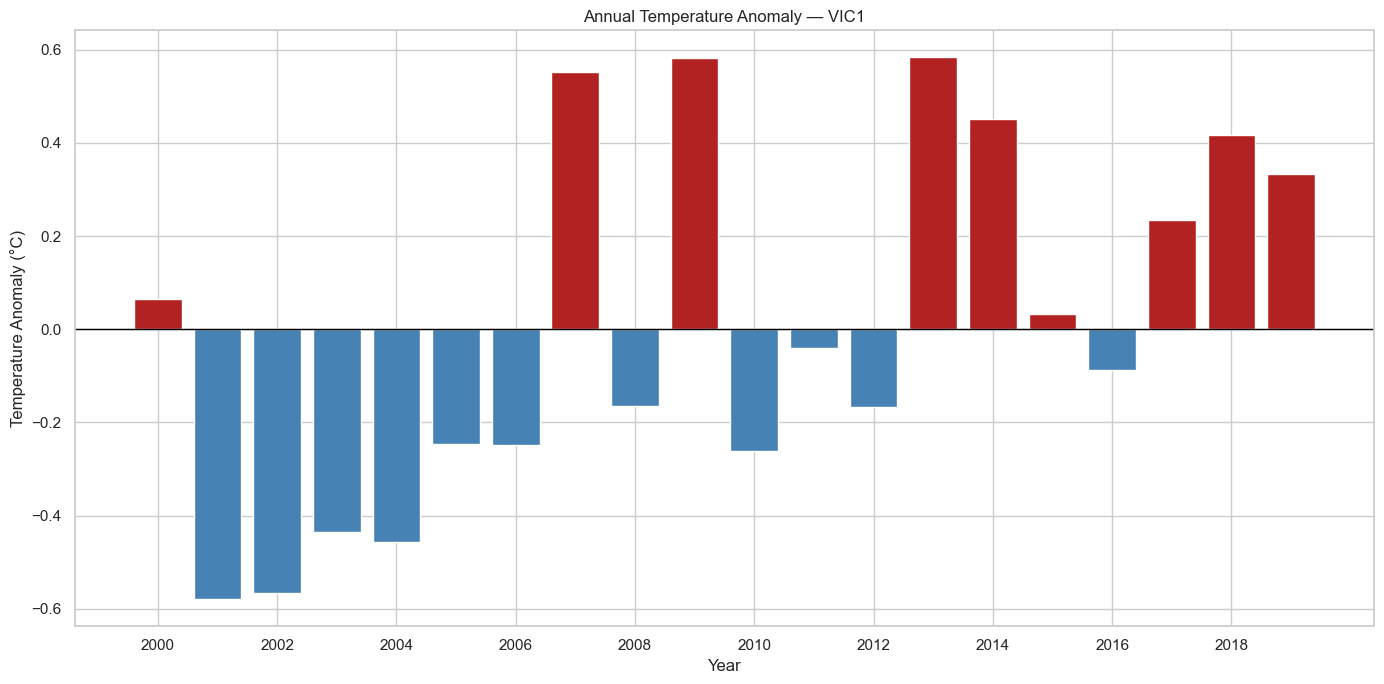

In [18]:
region = "SA1"

region_annual = dfannual[
    dfannual["REGION"] == region
].copy()

baseline = region_annual["mean_temp"].mean()

region_annual["temp_anomaly"] = (
    region_annual["mean_temp"] - baseline
)

sns.set_theme(style="whitegrid")

plt.figure(figsize=(14, 7))

colors = [
    "steelblue" if x < 0 else "firebrick"
    for x in region_annual["temp_anomaly"]
]

plt.bar(
    region_annual["year"],
    region_annual["temp_anomaly"],
    color=colors,
    width=0.8
)

plt.axhline(0, color="black", linewidth=1)
plt.xticks(range(2000, 2020, 2))
plt.xlabel("Year")
plt.ylabel("Temperature Anomaly (°C)")
plt.title("Annual Temperature Anomaly — VIC1")

plt.tight_layout()
plt.show()

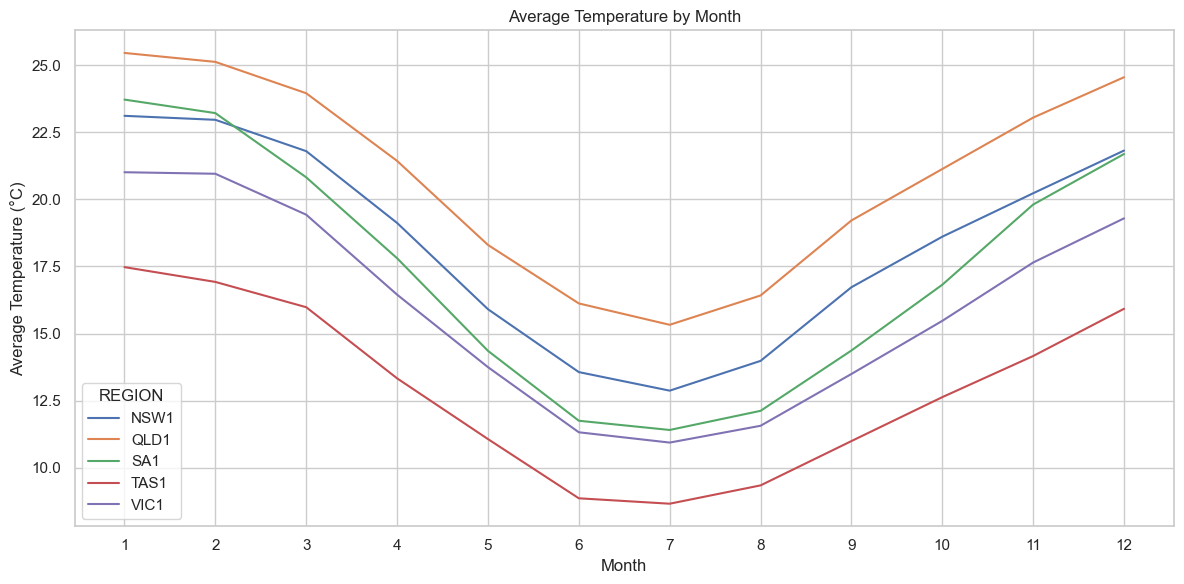

In [19]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=dfmonthly,
    x="month",
    y="temp_mean",
    hue="REGION",
    errorbar=None
)

plt.xlabel("Month")
plt.ylabel("Average Temperature (°C)")
plt.title("Average Temperature by Month")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

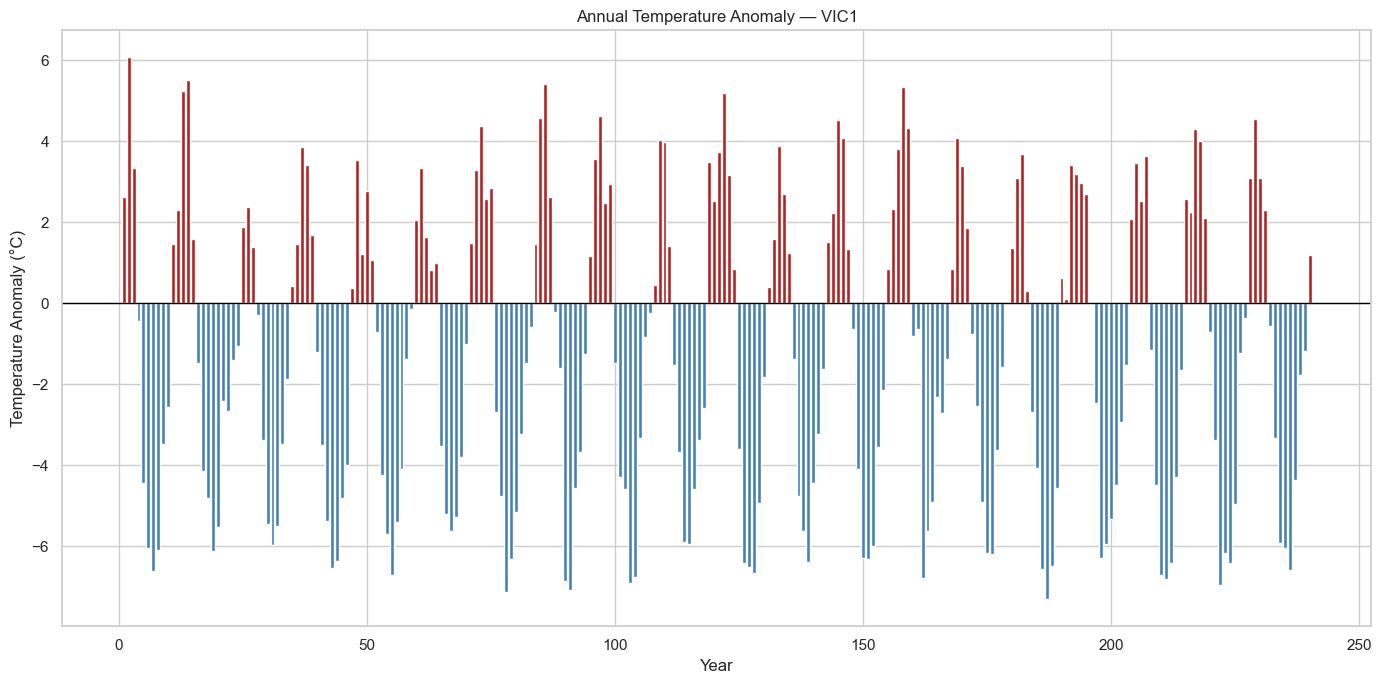

In [20]:
region = "VIC1"

region_monthly = dfmonthly[
    dfmonthly["REGION"] == region
].copy()

baseline_monthly = region_monthly["temp_mean"].mean()

region_monthly["temp_anomaly"] = (
    region_monthly["temp_mean"] - baseline
)

sns.set_theme(style="whitegrid")

plt.figure(figsize=(14, 7))

colors = [
    "steelblue" if x < 0 else "firebrick"
    for x in region_monthly["temp_anomaly"]
]

plt.bar(
    region_monthly["month_cumulative"],
    region_monthly["temp_anomaly"],
    color=colors,
    width=0.8
)

plt.axhline(0, color="black", linewidth=1)

plt.xlabel("Year")
plt.ylabel("Temperature Anomaly (°C)")
plt.title("Annual Temperature Anomaly — VIC1")

plt.tight_layout()
plt.show()

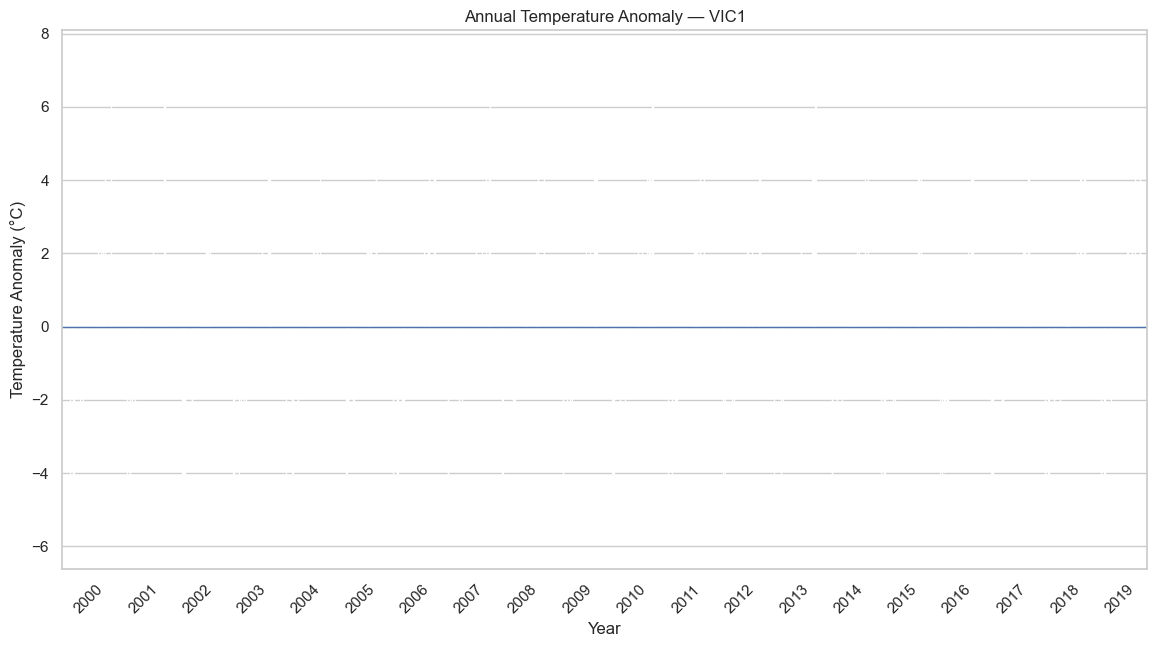

In [21]:
region = "VIC1"

region_monthly = dfmonthly[
    dfmonthly["REGION"] == region
].copy()

baseline = region_monthly["temp_mean"].mean()

region_monthly["temp_anomaly"] = (
    region_monthly["temp_mean"] - baseline
)

plt.figure(figsize=(14, 7))

sns.barplot(
    data=region_monthly,
    x="year",
    y="temp_anomaly",
    hue="temp_anomaly",
    palette=[
        "#4169A1" if x < 0 else "#C62828"
        for x in region_monthly["temp_anomaly"]
    ],
    legend=False
)

plt.axhline(0, linewidth=1)

plt.xlabel("Year")
plt.ylabel("Temperature Anomaly (°C)")
plt.title(f"Annual Temperature Anomaly — {region}")
plt.xticks(rotation=45)

#plt.tight_layout()
plt.show()

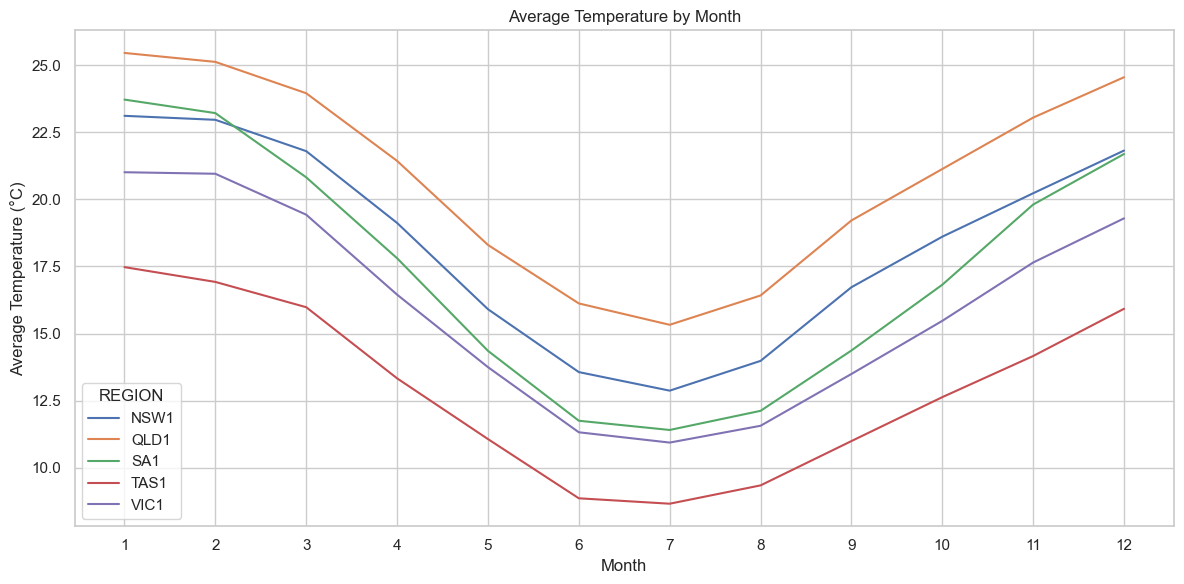

In [22]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=dfmonthly,
    x="month",
    y="temp_mean",
    hue="REGION",
    errorbar=None
)

plt.xlabel("Month")
plt.ylabel("Average Temperature (°C)")
plt.title("Average Temperature by Month")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

In [23]:
rooftop_raw = pd.read_excel(
    "Rooftop PV data.xlsx",
    sheet_name="Sheet2"
)

rooftop_raw = rooftop_raw.rename(
    columns={"Unnamed: 0": "state"}
)

rooftop_raw = rooftop_raw.drop(columns=[2021])
rooftop_raw = rooftop_raw.drop(columns=["2021.1"])

rooftop_long = rooftop_raw.melt(
    id_vars="state",
    var_name="year",
    value_name="rooftop_pv_kw"
)

#Convert to numeric
rooftop_long["year"] = pd.to_numeric(
    rooftop_long["year"],
    errors="coerce"
)
rooftop_long["rooftop_pv_kw"] = pd.to_numeric(
    rooftop_long["rooftop_pv_kw"],
    errors="coerce"
)

rooftop_long.tail(5)

,state,year,rooftop_pv_kw
115,VIC,2020,2599839.681
116,QLD,2020,3709417.548
117,SA,2020,1541248.873
118,WA,2020,1651493.386
119,TAS,2020,183860.422


In [24]:
region_to_state = {
    "VIC1": "VIC",
    "NSW1": "NSW",
    "QLD1": "QLD",
    "SA1": "SA",
    "TAS1": "TAS"
}

dfannual["state"] = dfannual["REGION"].map(region_to_state)

annual_with_pv = dfannual.merge(
    rooftop_long,
    on=["state", "year"],
    how="left"
)

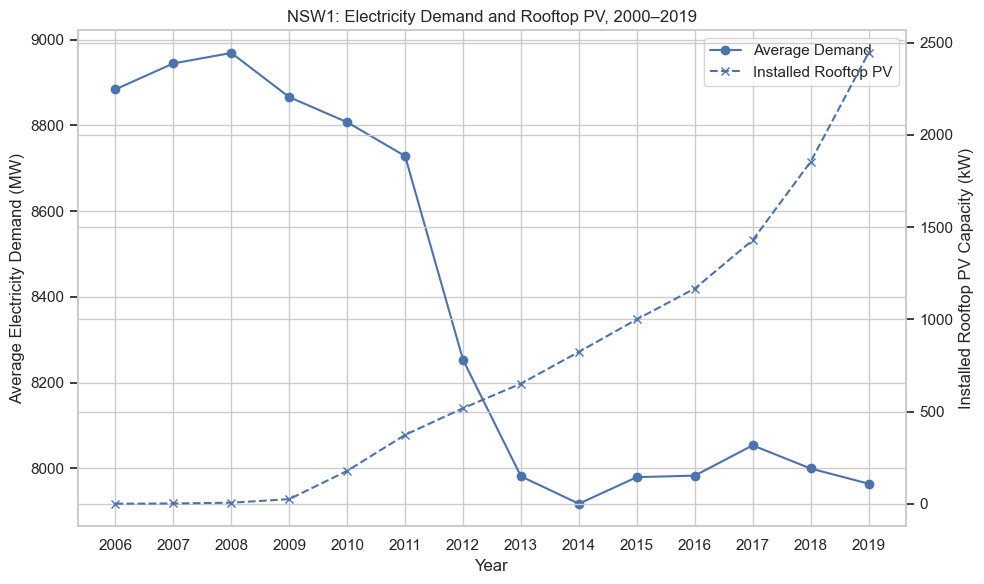

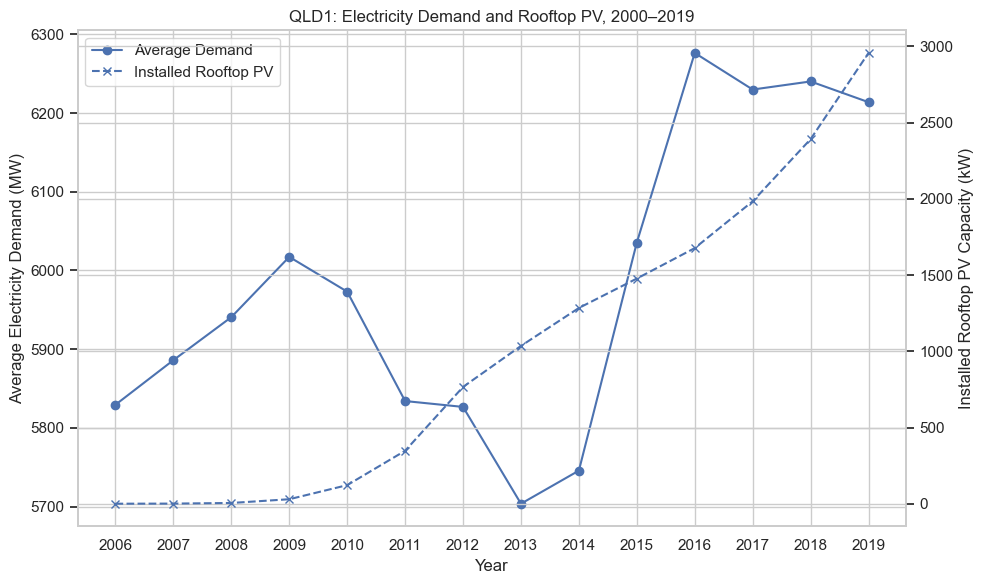

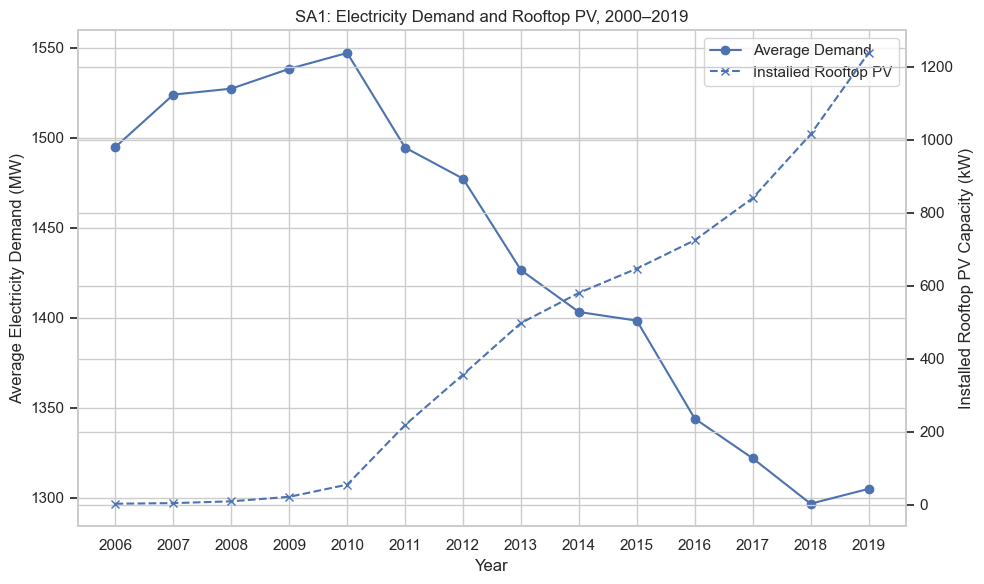

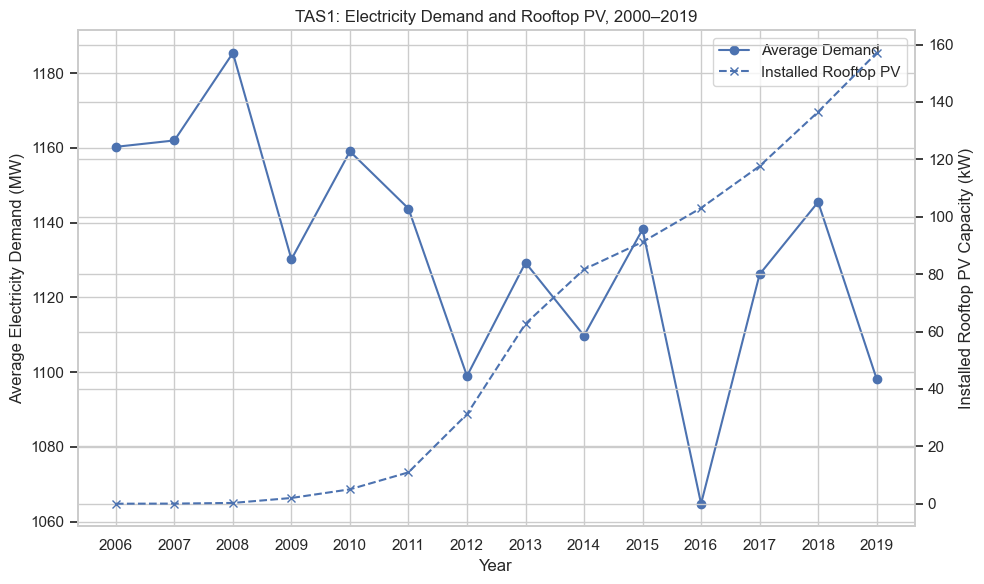

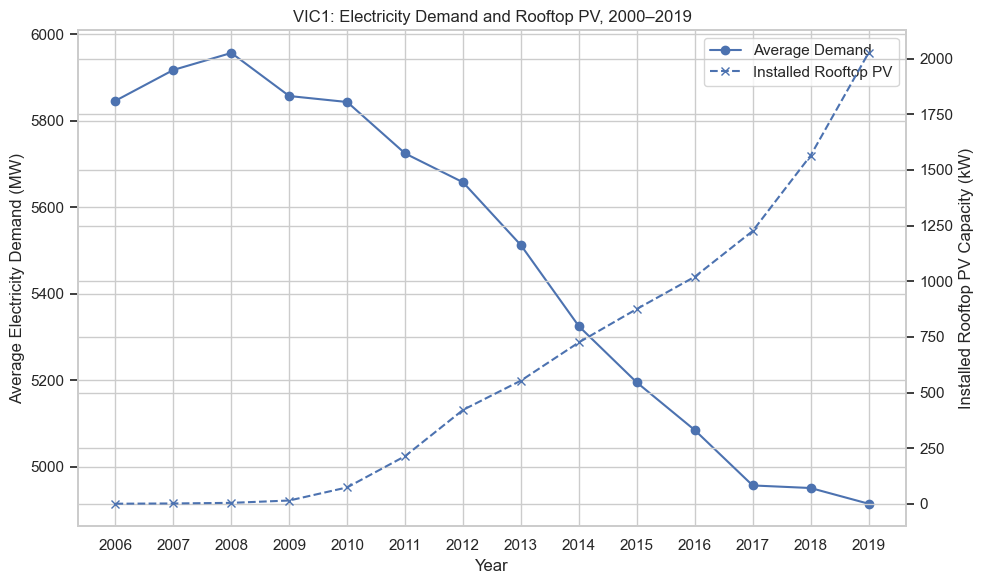

In [25]:
pv_analysis = annual_with_pv.dropna(
    subset=["year", "mean_demand", "rooftop_pv_kw"]
).copy()

for region, data in pv_analysis.groupby("REGION"):

    fig, ax1 = plt.subplots(figsize=(10, 6))

    # Demand
    ax1.plot(
        data["year"],
        data["mean_demand"],
        marker="o",
        label="Average Demand"
    )

    ax1.set_xlabel("Year")
    ax1.set_ylabel("Average Electricity Demand (MW)")

    # PV
    ax2 = ax1.twinx()

    ax2.plot(
        data["year"],
        data["rooftop_pv_kw"]/1000,
        marker="x",
        linestyle="--",
        label="Installed Rooftop PV"
    )

    ax2.set_ylabel("Installed Rooftop PV Capacity (kW)")

    plt.title(
        f"{region}: Electricity Demand and Rooftop PV, 2000–2019"
    )

    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()

    ax1.legend(
        lines1 + lines2,
        labels1 + labels2,
        loc="best"
    )

    ax1.set_xticks(data["year"])
    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()

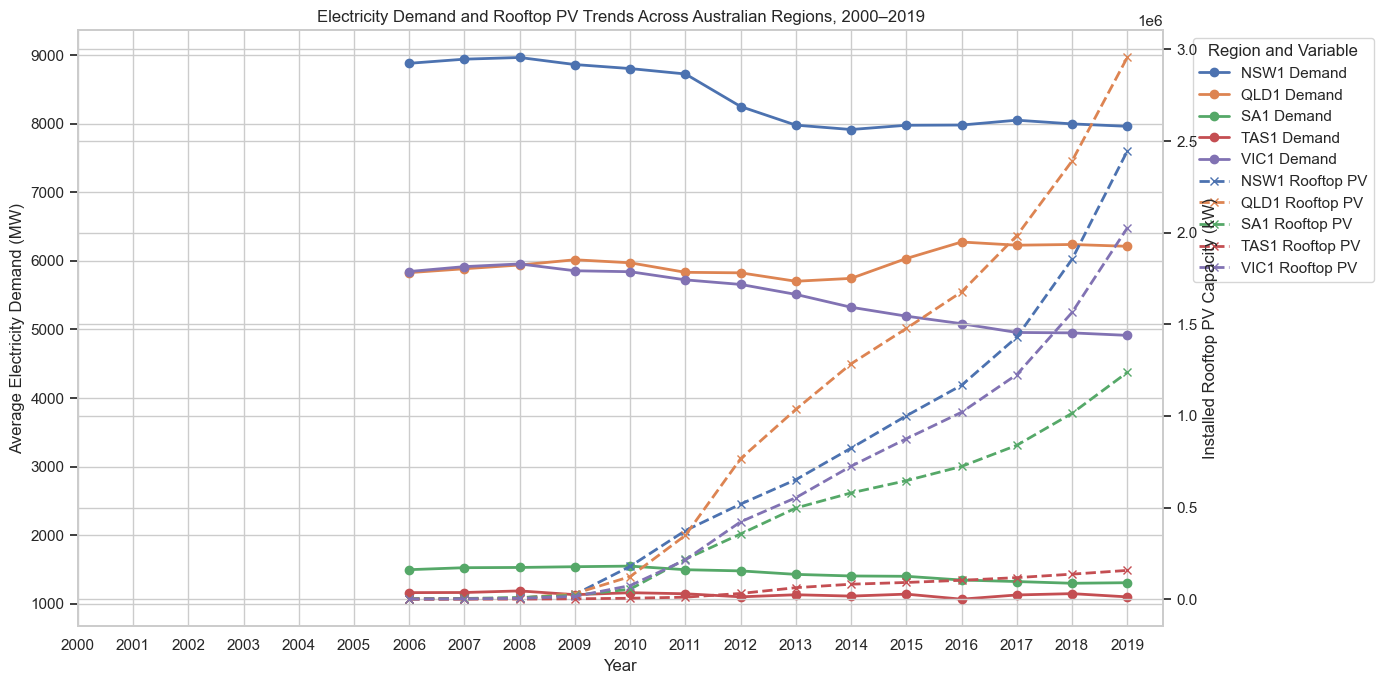

In [26]:


pv_analysis = pv_analysis.sort_values(["REGION", "year"])

fig, ax1 = plt.subplots(figsize=(14, 7))

# Demand
for region, data in pv_analysis.groupby("REGION"):
    ax1.plot(
        data["year"],
        data["mean_demand"],
        marker="o",
        linewidth=2,
        label=f"{region} Demand"
    )

ax1.set_xlabel("Year")
ax1.set_ylabel("Average Electricity Demand (MW)")

# PV
ax2 = ax1.twinx()

for region, data in pv_analysis.groupby("REGION"):
    ax2.plot(
        data["year"],
        data["rooftop_pv_kw"],
        marker="x",
        linestyle="--",
        linewidth=2,
        label=f"{region} Rooftop PV"
    )

ax2.set_ylabel("Installed Rooftop PV Capacity (kW)")

# Combined legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    title="Region and Variable",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

ax1.set_xticks(range(2000, 2020))

plt.title(
    "Electricity Demand and Rooftop PV Trends Across Australian Regions, 2000–2019"
)

plt.tight_layout()
plt.show()

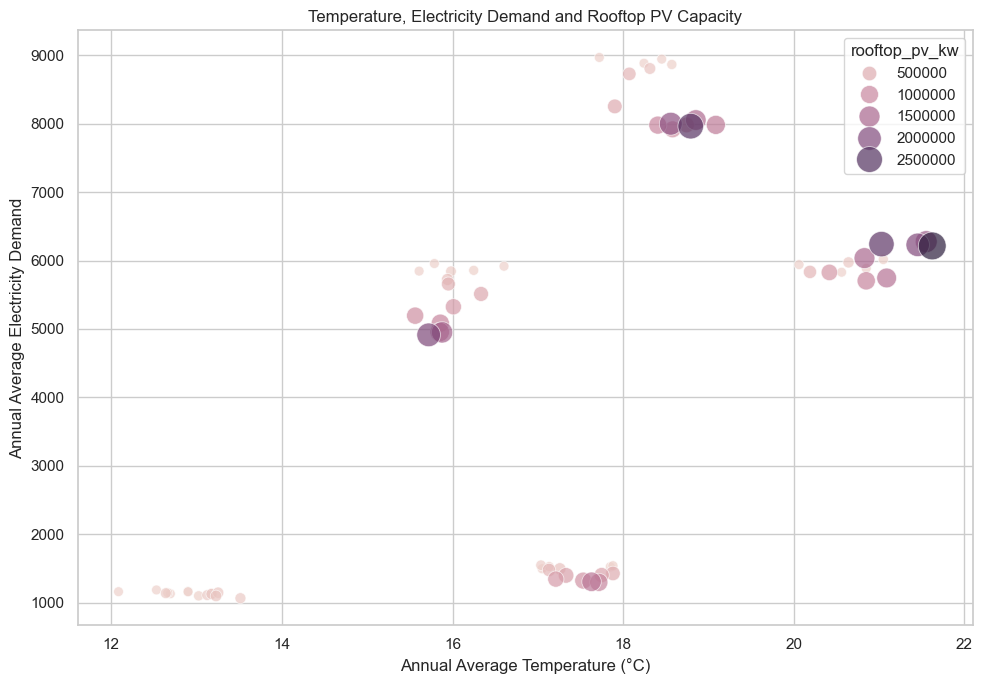

In [27]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pv_analysis,
    x="mean_temp",
    y="mean_demand",
    size="rooftop_pv_kw",
    hue="rooftop_pv_kw",
    sizes=(50, 400),
    alpha=0.7
)

plt.title(
    "Temperature, Electricity Demand and Rooftop PV Capacity"
)

plt.xlabel("Annual Average Temperature (°C)")
plt.ylabel("Annual Average Electricity Demand")

plt.tight_layout()
plt.show()

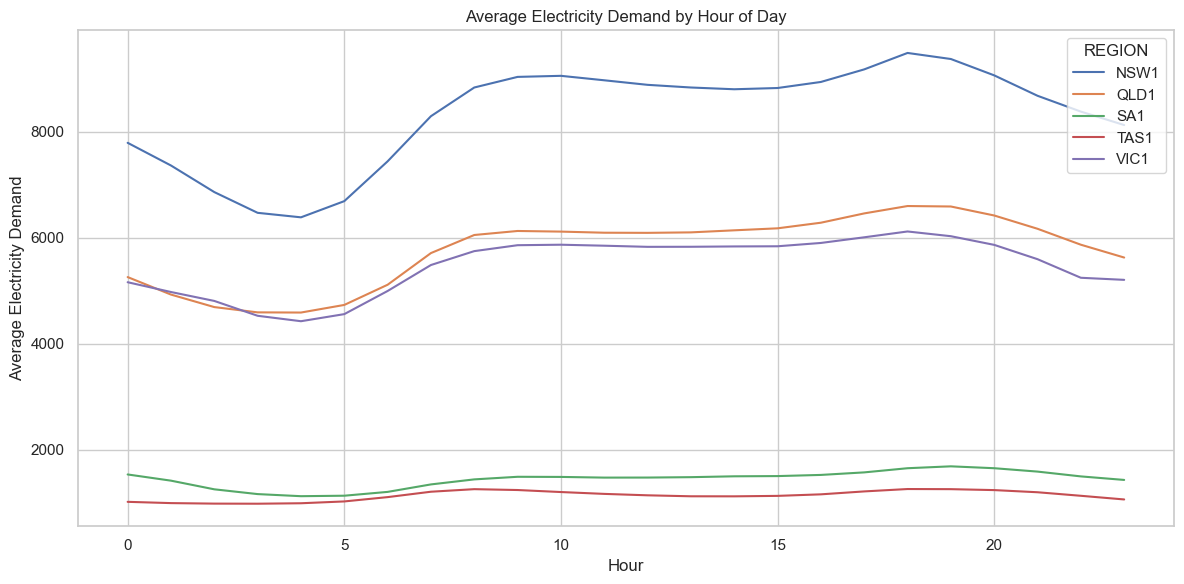

In [28]:
hourly_demand = (
    df.groupby(["REGION", "hour"])
    ["TOTALDEMAND"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=hourly_demand,
    x="hour",
    y="TOTALDEMAND",
    hue="REGION"
)

plt.title("Average Electricity Demand by Hour of Day")
plt.xlabel("Hour")
plt.ylabel("Average Electricity Demand")

plt.tight_layout()
plt.show()

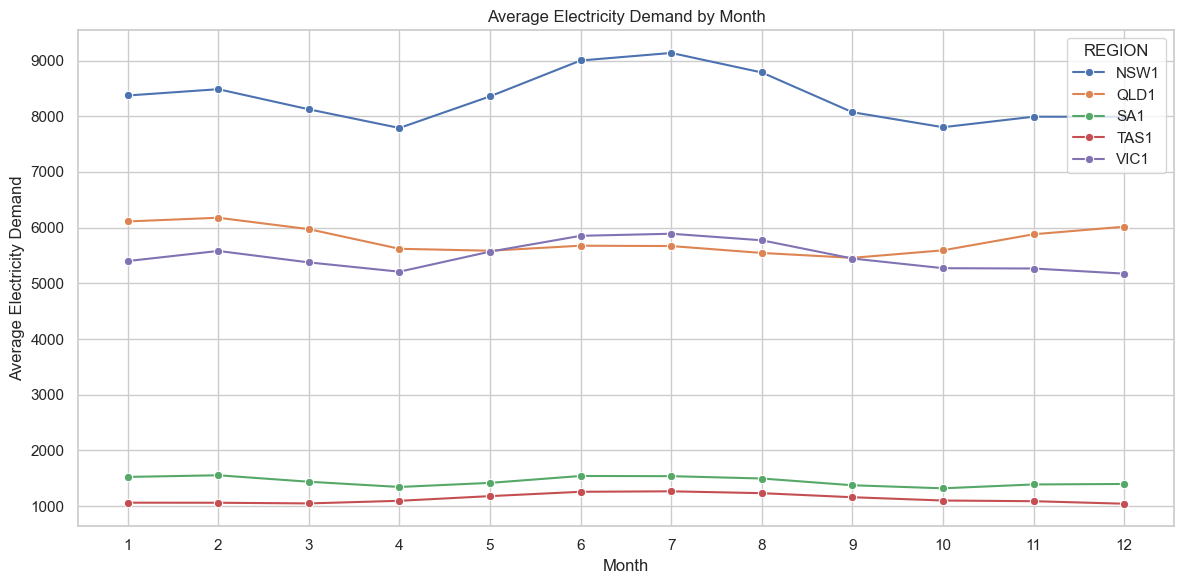

In [29]:
monthly_demand = (
    df.groupby(["REGION", "month"])
    ["TOTALDEMAND"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_demand,
    x="month",
    y="TOTALDEMAND",
    hue="REGION",
    marker="o"
)

plt.xticks(range(1, 13))

plt.title("Average Electricity Demand by Month")
plt.xlabel("Month")
plt.ylabel("Average Electricity Demand")

plt.tight_layout()
plt.show()

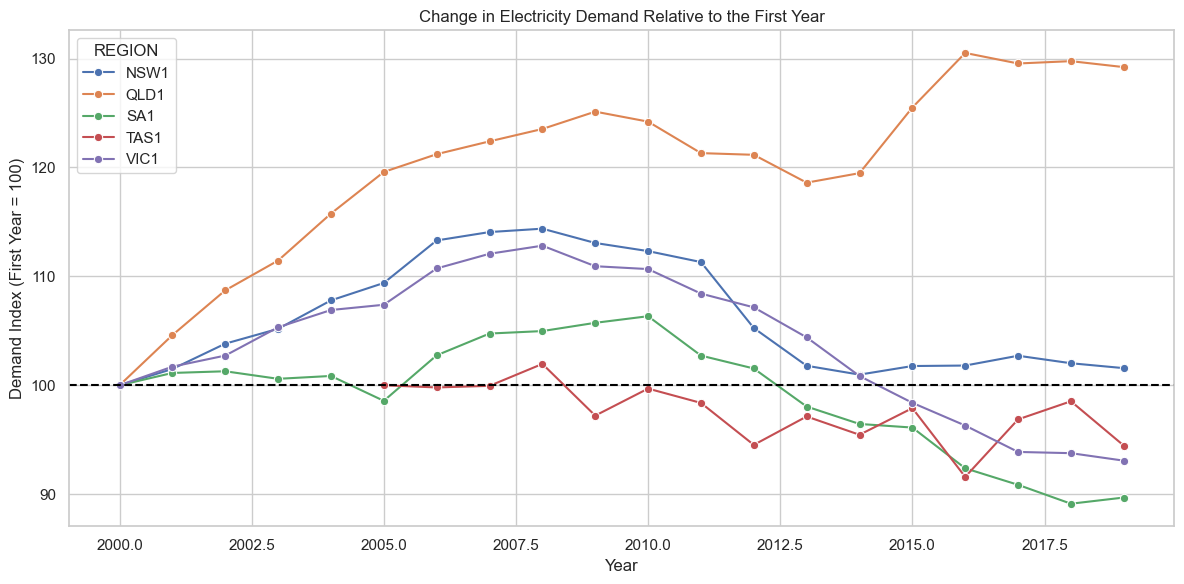

In [30]:
df["demand_normalised"] = (
    df.groupby("REGION")["TOTALDEMAND"]
      .transform(
          lambda x: (x - x.min()) / (x.max() - x.min())
      )
)

dfannual["demand_index"] = (
    dfannual.groupby("REGION")["mean_demand"]
          .transform(lambda x: (x / x.iloc[0]) * 100)
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=dfannual,
    x="year",
    y="demand_index",
    hue="REGION",
    marker="o"
)

plt.axhline(100, linestyle="--", color="black")

plt.title("Change in Electricity Demand Relative to the First Year")
plt.xlabel("Year")
plt.ylabel("Demand Index (First Year = 100)")

plt.tight_layout()
plt.show()

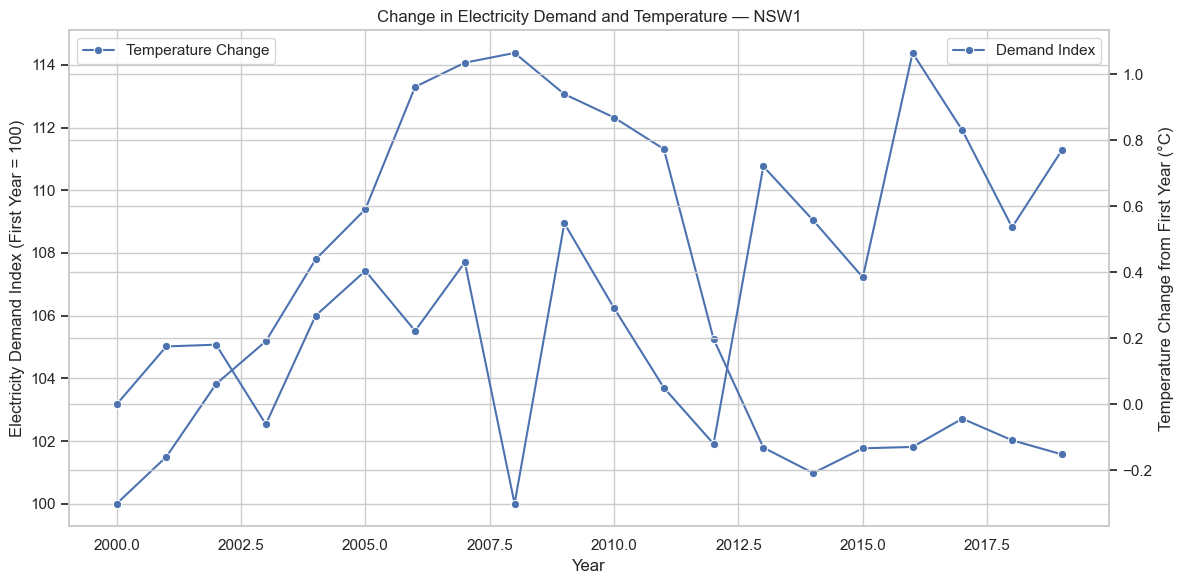

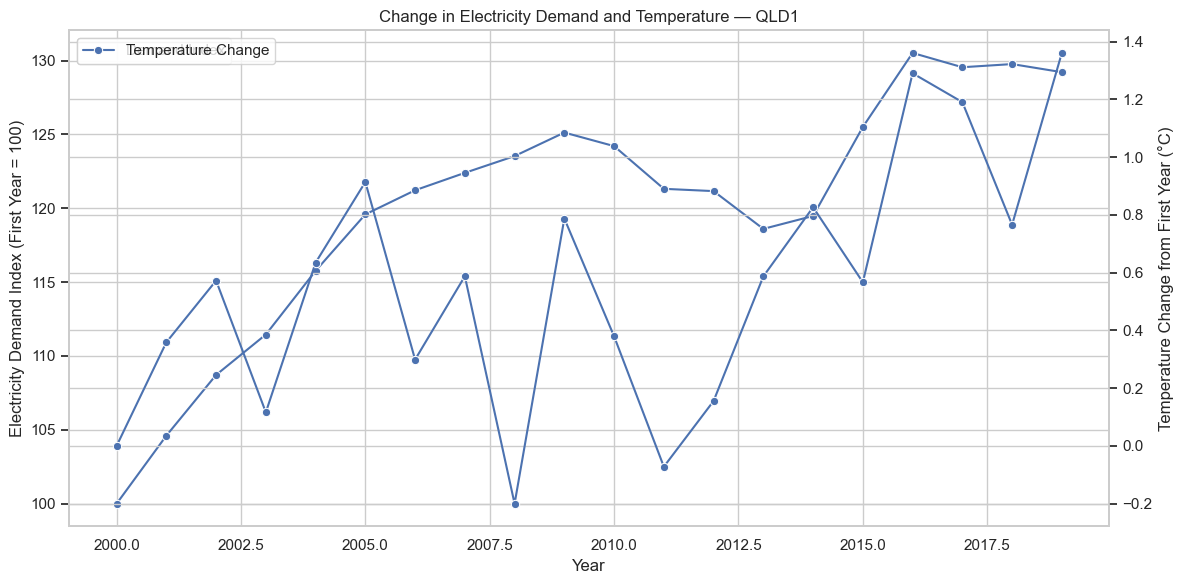

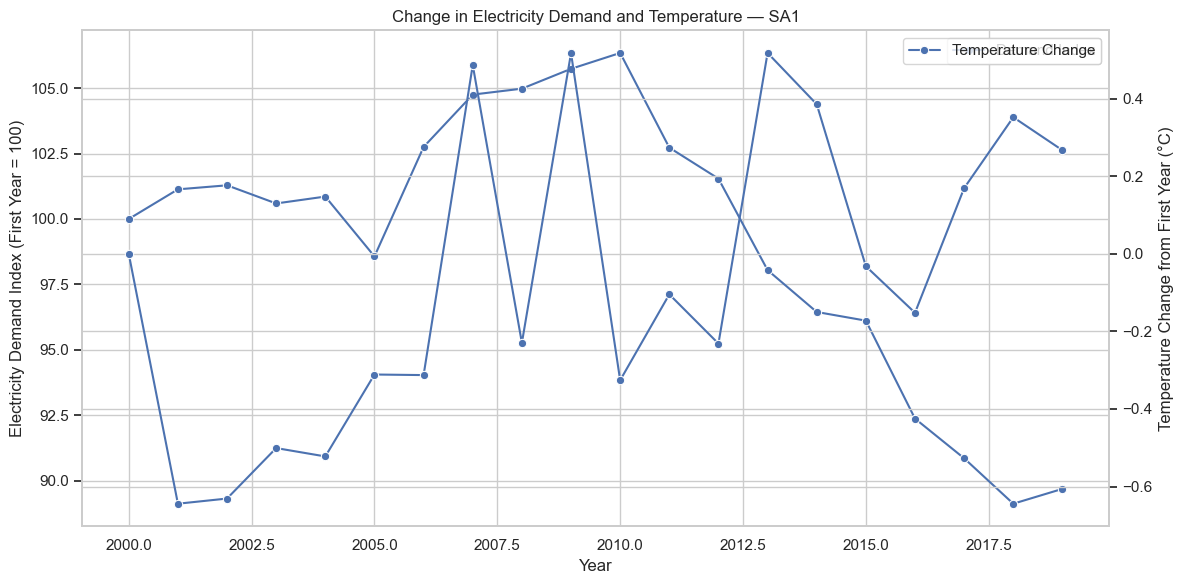

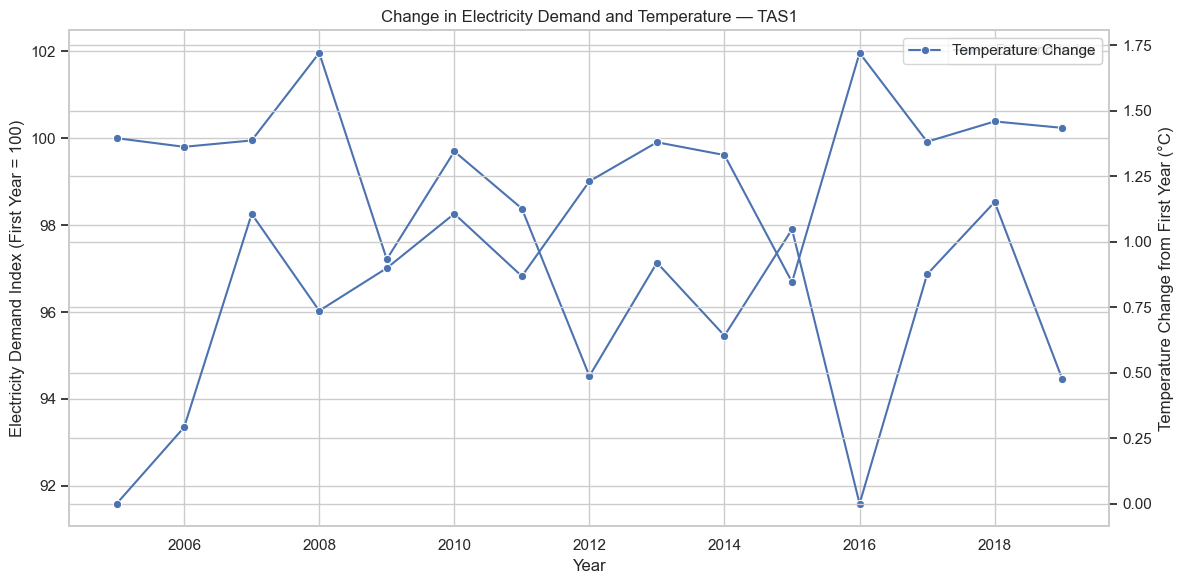

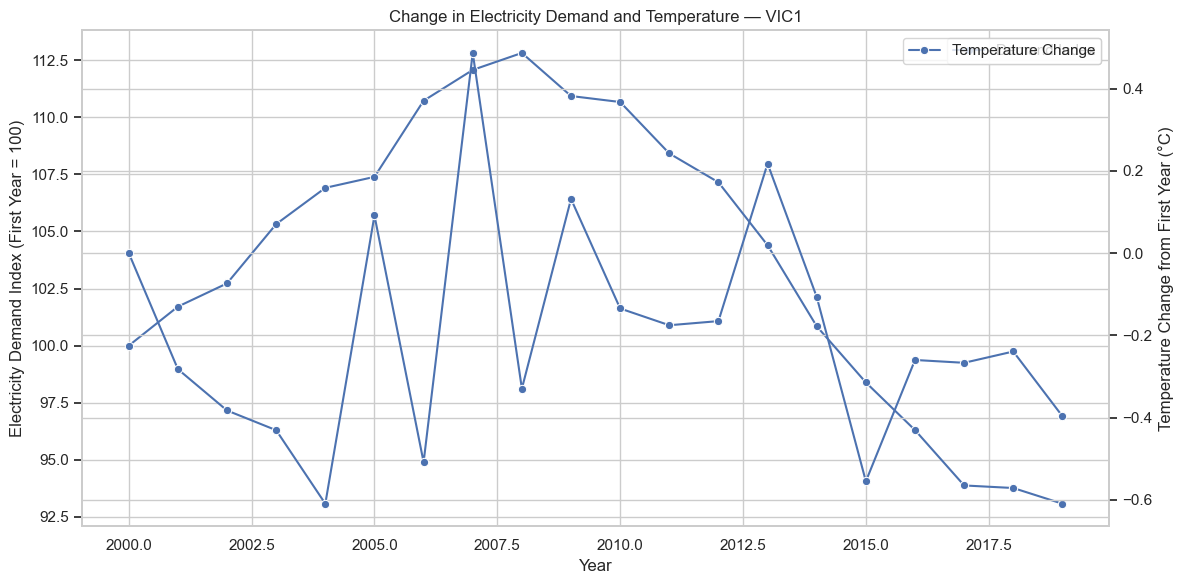

In [31]:
annual = dfannual.sort_values(["REGION", "year"]).copy()

annual["first_demand"] = (
    annual.groupby("REGION")["mean_demand"]
          .transform("first")
)
annual["first_temp"] = (
    annual.groupby("REGION")["mean_temp"]
          .transform("first")
)

annual["demand_index"] = (
    annual["mean_demand"] /
    annual["first_demand"] * 100
)

annual["temp_change_from_first"] = (
    annual["mean_temp"] -
    annual["first_temp"]
)

regions = annual["REGION"].unique()

for region in regions:

    region_data = annual[
        annual["REGION"] == region
    ].sort_values("year")

    fig, ax1 = plt.subplots(figsize=(12, 6))

    # Demand index
    sns.lineplot(
        data=region_data,
        x="year",
        y="demand_index",
        marker="o",
        ax=ax1,
        label="Demand Index"
    )

    ax1.set_xlabel("Year")
    ax1.set_ylabel("Electricity Demand Index (First Year = 100)")

    # Temperature change
    ax2 = ax1.twinx()

    sns.lineplot(
        data=region_data,
        x="year",
        y="temp_change_from_first",
        marker="o",
        ax=ax2,
        label="Temperature Change"
    )

    ax2.set_ylabel("Temperature Change from First Year (°C)")

    plt.title(
        f"Change in Electricity Demand and Temperature — {region}"
    )

    plt.tight_layout()
    plt.show()

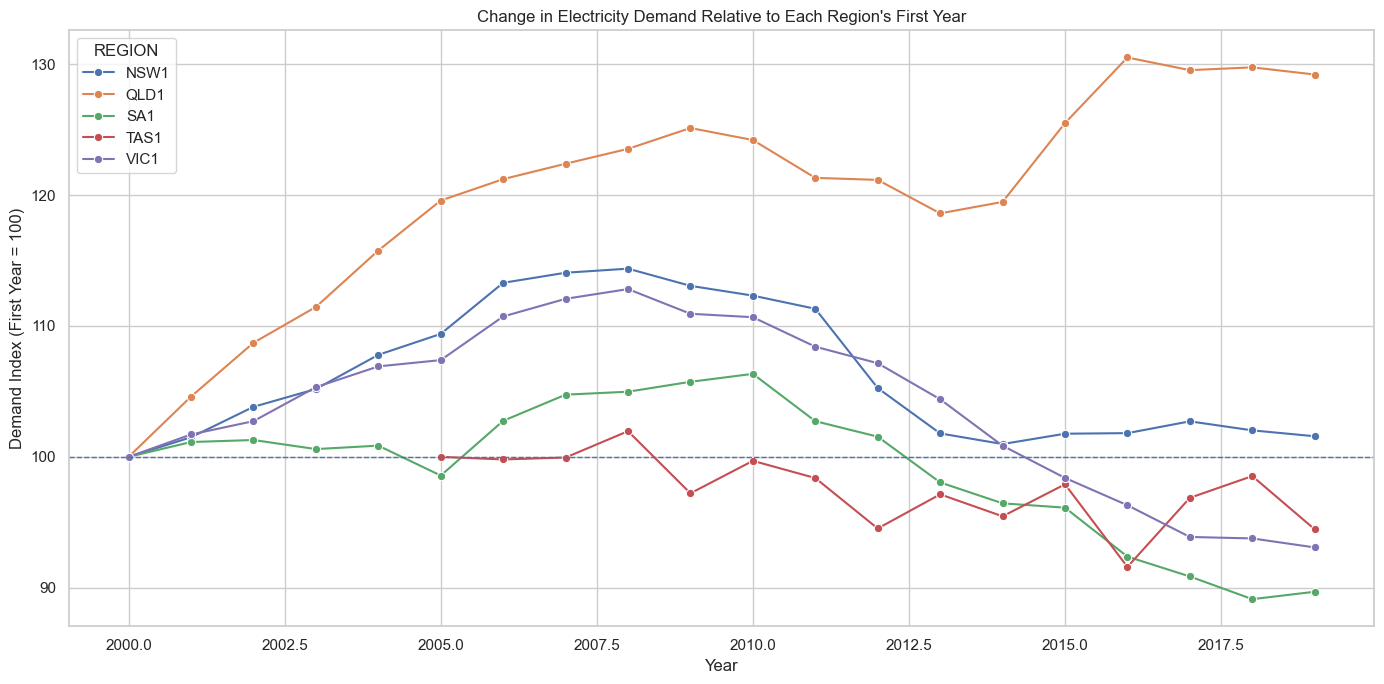

In [32]:
plt.figure(figsize=(14, 7))

sns.lineplot(
    data=annual,
    x="year",
    y="demand_index",
    hue="REGION",
    marker="o"
)

plt.axhline(
    100,
    linestyle="--",
    linewidth=1
)

plt.title(
    "Change in Electricity Demand Relative to Each Region's First Year"
)

plt.xlabel("Year")
plt.ylabel("Demand Index (First Year = 100)")

plt.tight_layout()
plt.show()

     REGION  month  year  demand_mean   demand_max  demand_min  temp_mean  \
0      NSW1      1  2000  7153.476519  10404.95167  4650.29167  20.904720   
1      NSW1      1  2001  7892.775532  11547.42833  4973.09833  23.415048   
2      NSW1      1  2002  7835.624325  10981.60500  5322.12167  22.843660   
3      NSW1      1  2003  8081.132294  12331.45167  5344.19167  22.879583   
4      NSW1      1  2004  8265.071207  11690.89833  5730.18000  23.112307   
...     ...    ...   ...          ...          ...         ...        ...   
1131   VIC1     12  2015  5159.338703   8579.90000  3497.10000  20.706989   
1132   VIC1     12  2016  4543.491934   7281.10000  3201.67000  19.365039   
1133   VIC1     12  2017  4719.066720   8411.07000  3192.04000  19.538911   
1134   VIC1     12  2018  4641.963965   8465.35000  3284.96000  20.377621   
1135   VIC1     12  2019  4597.458125   9113.24000  3136.49000  18.488441   

      temp_max  temp_min  humidity_mean  precipitation  month_cumulative  \

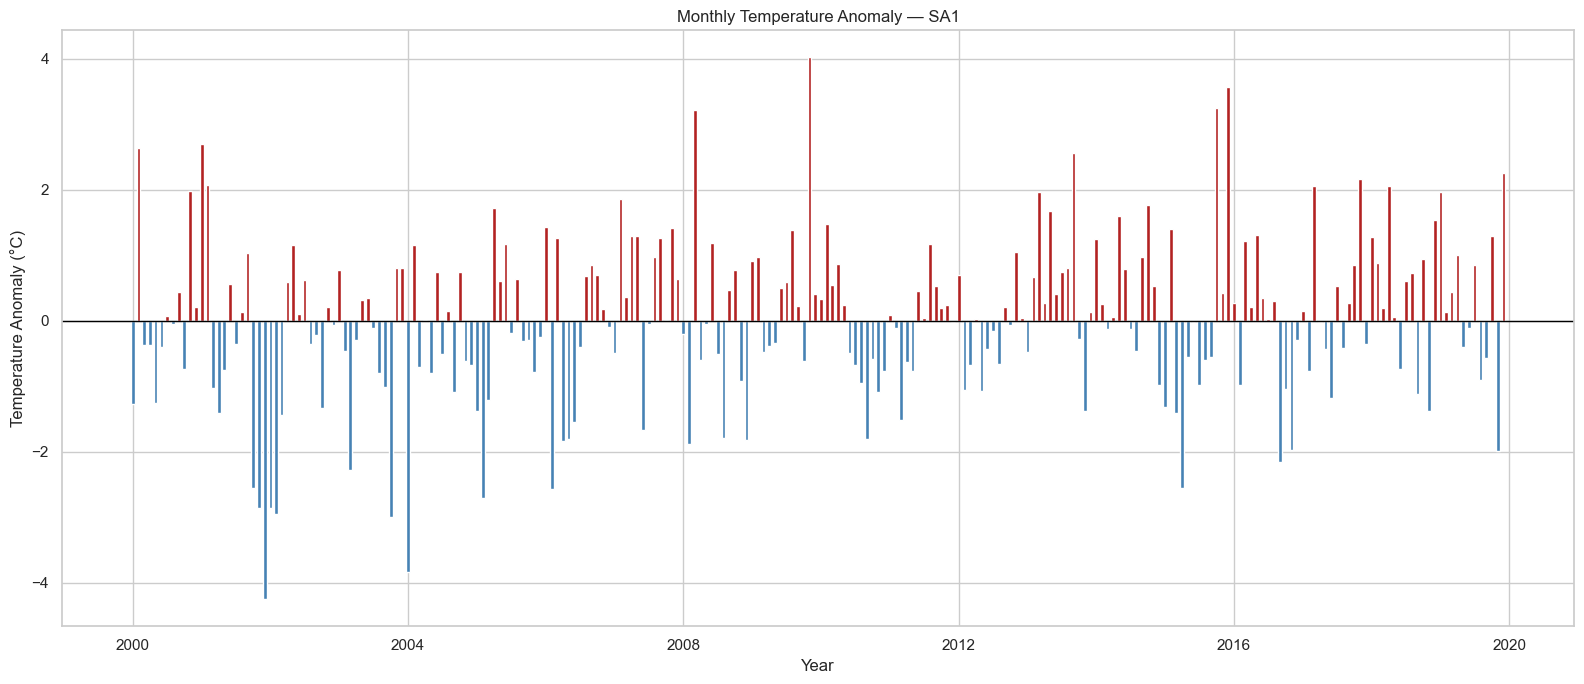

In [33]:
dfmonthly["monthly_baseline"] = (
    dfmonthly.groupby(["REGION", "month"])["temp_mean"]
           .transform("mean")
)

dfmonthly["temp_anomaly"] = (
    dfmonthly["temp_mean"] -
    dfmonthly["monthly_baseline"]
)

dfmonthly["date"] = pd.to_datetime(
    dict(
        year=dfmonthly["year"],
        month=dfmonthly["month"],
        day=1
    )
)

print(dfmonthly)
region = "SA1"

monthly_region = dfmonthly[
    dfmonthly["REGION"] == region
].copy()

plt.figure(figsize=(16, 7))

colors = [
    "steelblue" if x < 0 else "firebrick"
    for x in monthly_region["temp_anomaly"]
]

plt.bar(
    monthly_region["date"],
    monthly_region["temp_anomaly"],
    color=colors,
    width=20
)

plt.axhline(
    0,
    color="black",
    linewidth=1
)

plt.title(
    f"Monthly Temperature Anomaly — {region}"
)

plt.xlabel("Year")
plt.ylabel("Temperature Anomaly (°C)")

plt.tight_layout()
plt.show()

In [34]:
dfmonthly

,REGION,month,year,demand_mean,demand_max,demand_min,temp_mean,temp_max,temp_min,humidity_mean,precipitation,month_cumulative,monthly_baseline,temp_anomaly,date
0,NSW1,1,2000,7153.476519,10404.95167,4650.29167,20.904720,34.7,14.8,68.898854,19.6,1,23.112920,-2.208200,2000-01-01
1,NSW1,1,2001,7892.775532,11547.42833,4973.09833,23.415048,31.6,16.5,73.932969,110.4,13,23.112920,0.302128,2001-01-01
2,NSW1,1,2002,7835.624325,10981.60500,5322.12167,22.843660,36.8,16.0,67.630569,26.6,25,23.112920,-0.269260,2002-01-01
3,NSW1,1,2003,8081.132294,12331.45167,5344.19167,22.879583,38.6,16.2,67.763889,3.6,37,23.112920,-0.233337,2003-01-01
4,NSW1,1,2004,8265.071207,11690.89833,5730.18000,23.112307,32.8,16.5,71.354405,20.8,49,23.112920,-0.000613,2004-01-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1131,VIC1,12,2015,5159.338703,8579.90000,3497.10000,20.706989,40.5,9.4,59.553091,30.6,192,19.291967,1.415023,2015-12-01
1132,VIC1,12,2016,4543.491934,7281.10000,3201.67000,19.365039,37.7,8.9,61.276042,20.4,204,19.291967,0.073072,2016-12-01
1133,VIC1,12,2017,4719.066720,8411.07000,3192.04000,19.538911,37.1,10.9,65.576613,43.8,216,19.291967,0.246945,2017-12-01
1134,VIC1,12,2018,4641.963965,8465.35000,3284.96000,20.377621,37.9,10.5,68.382392,41.2,228,19.291967,1.085654,2018-12-01


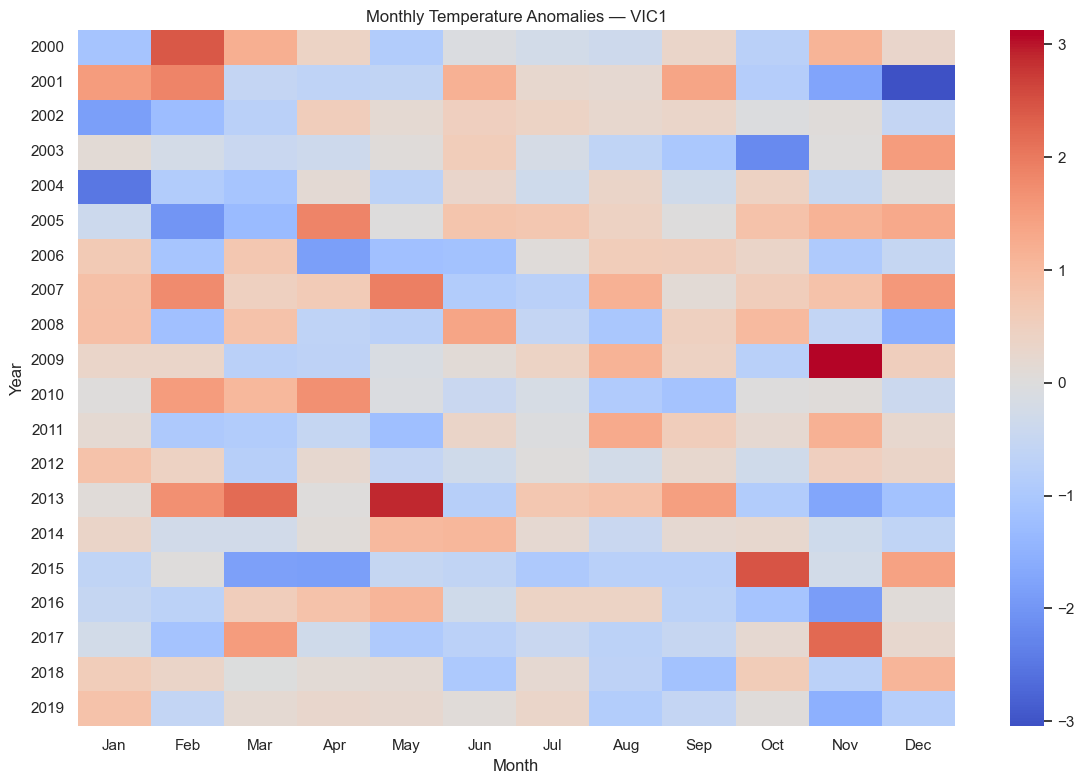

In [35]:
region = "VIC1"

dfmonthly["temp_anomaly"] = (
    dfmonthly["temp_mean"] -
    dfmonthly["monthly_baseline"]
)

monthly_region = dfmonthly[
    dfmonthly["REGION"] == region
]

anomaly_matrix = monthly_region.pivot(
    index="year",
    columns="month",
    values="temp_anomaly"
)

plt.figure(figsize=(12, 8))
anomaly_matrix.columns = [
    "Jan", "Feb", "Mar", "Apr",
    "May", "Jun", "Jul", "Aug",
    "Sep", "Oct", "Nov", "Dec"
]
sns.heatmap(
    anomaly_matrix,
    cmap="coolwarm",
    center=0,
    annot=False
)

plt.title(
    f"Monthly Temperature Anomalies — {region}"
)

plt.xlabel("Month")
plt.ylabel("Year")

plt.tight_layout()
plt.show()

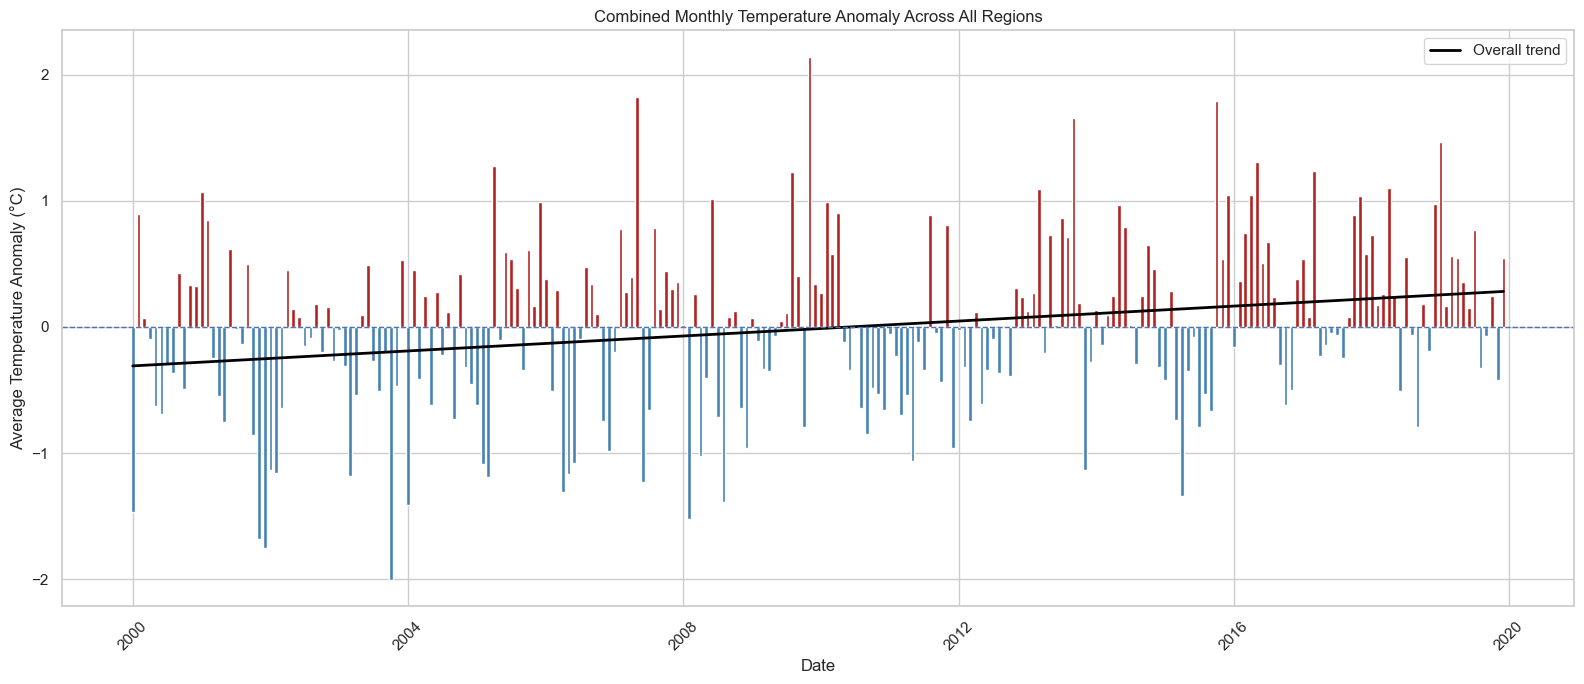

In [36]:
import numpy as np
monthly = dfmonthly.copy()

monthly["monthly_temp_baseline"] = (
    monthly.groupby(["REGION", "month"])["temp_mean"]
           .transform("mean")
)

monthly["temp_anomaly"] = (
    monthly["temp_mean"] -
    monthly["monthly_temp_baseline"]
)

monthly["date"] = pd.to_datetime(
    {
        "year": monthly["year"],
        "month": monthly["month"],
        "day": 1
    }
)

combined_monthly_anomaly = (
    monthly.groupby("date")
           .agg(
               mean_temp_anomaly=("temp_anomaly", "mean"),
               regions_available=("REGION", "nunique")
           )
           .reset_index()
)

sns.set_theme(style="whitegrid")

plt.figure(figsize=(16, 7))

# Positive = red, negative = blue
colors = [
    "steelblue" if x < 0 else "firebrick"
    for x in combined_monthly_anomaly["mean_temp_anomaly"]
]

# Monthly anomaly bars
plt.bar(
    combined_monthly_anomaly["date"],
    combined_monthly_anomaly["mean_temp_anomaly"],
    color=colors,
    width=20
)

# Create numerical x-values for the trend line
x = np.arange(len(combined_monthly_anomaly))
y = combined_monthly_anomaly["mean_temp_anomaly"]

# Calculate linear trend
trend = np.polyfit(x, y, 1)
trend_line = np.polyval(trend, x)

# Add overall trend line
plt.plot(
    combined_monthly_anomaly["date"],
    trend_line,
    color="black",
    linewidth=2,
    label="Overall trend"
)

# Zero line
plt.axhline(
    0,
    linestyle="--",
    linewidth=1
)

plt.title(
    "Combined Monthly Temperature Anomaly Across All Regions"
)

plt.xlabel("Date")
plt.ylabel("Average Temperature Anomaly (°C)")

plt.xticks(rotation=45)

plt.legend()

plt.tight_layout()
plt.show()

In [37]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error
monthly = dfmonthly.sort_values(
    ["REGION", "year", "month"]
).copy()

monthly["first_mean_demand"] = (
    monthly.groupby("REGION")["demand_mean"]
           .transform("first")
)

monthly["demand_index"] = (
    monthly["demand_mean"] /
    monthly["first_mean_demand"]
) * 100

model_data = monthly.dropna(
    subset=[
        "temp_anomaly",
        "demand_index"
    ]
).copy()

X = model_data[["temp_anomaly"]]

y = model_data["demand_index"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

linear_model = LinearRegression()

linear_model.fit(
    X_train,
    y_train
)

y_pred = linear_model.predict(X_test)

r2 = r2_score(
    y_test,
    y_pred
)

mae = mean_absolute_error(
    y_test,
    y_pred
)

print("R² Score:", r2)
print("MAE:", mae)

R² Score: 0.003633501314835863
MAE: 11.852736386775888


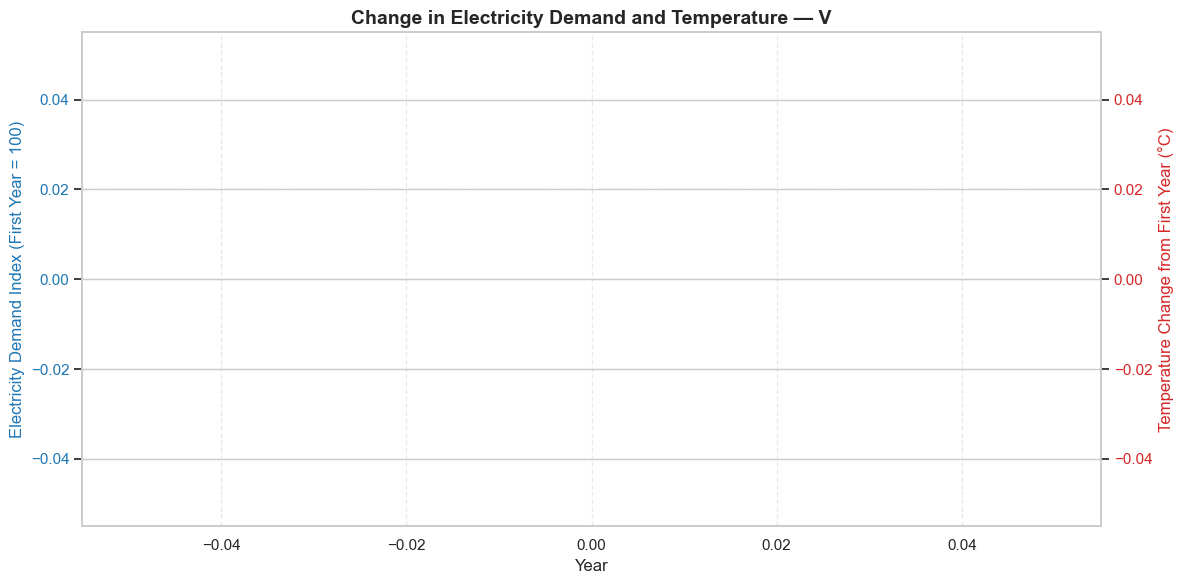

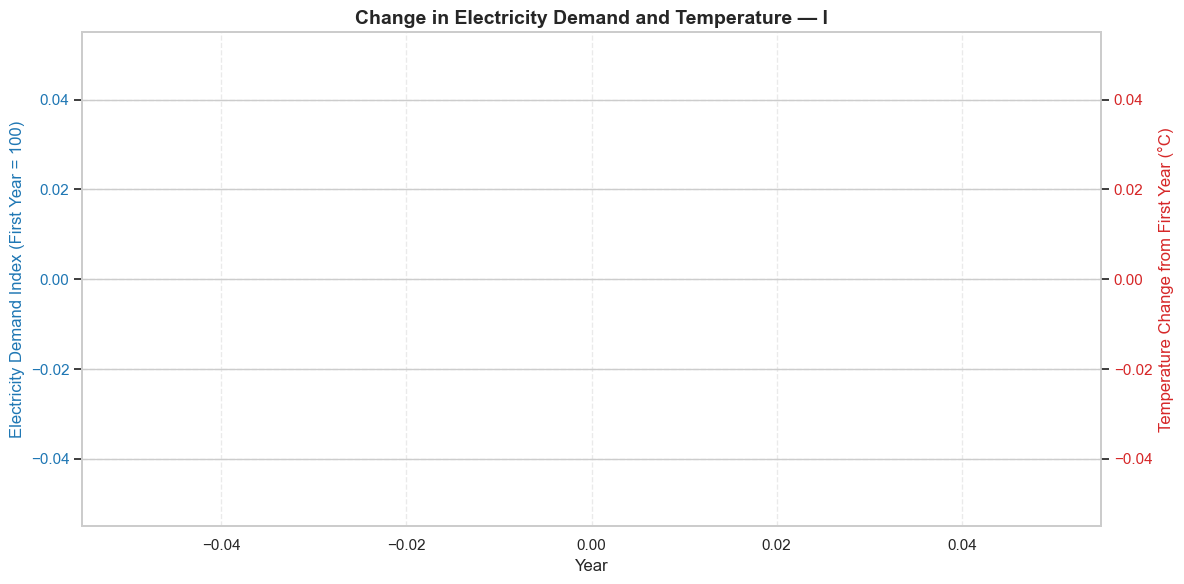

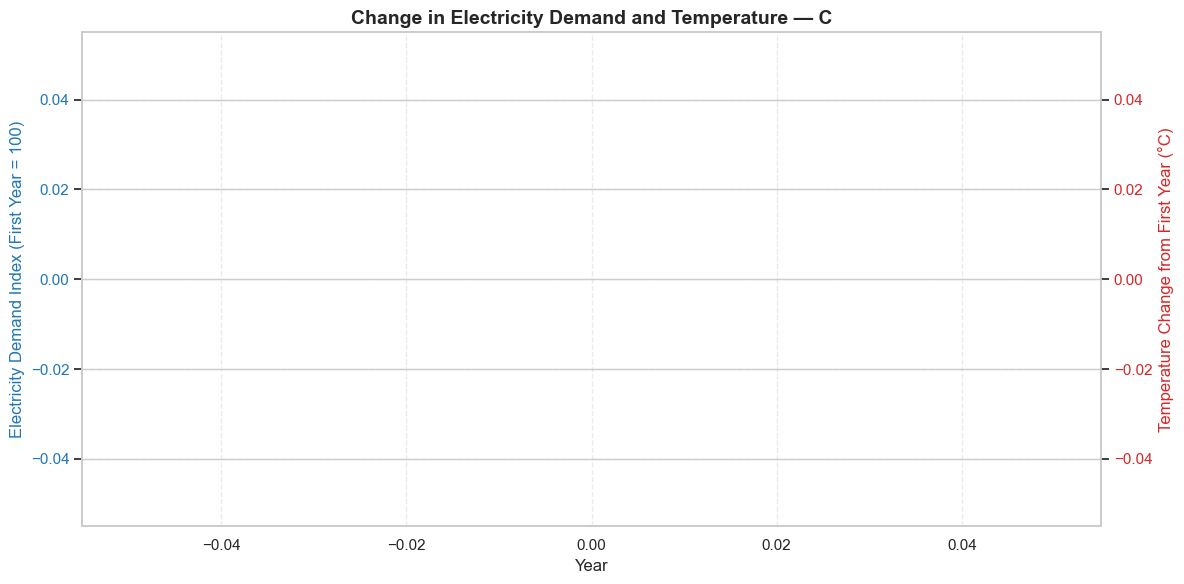

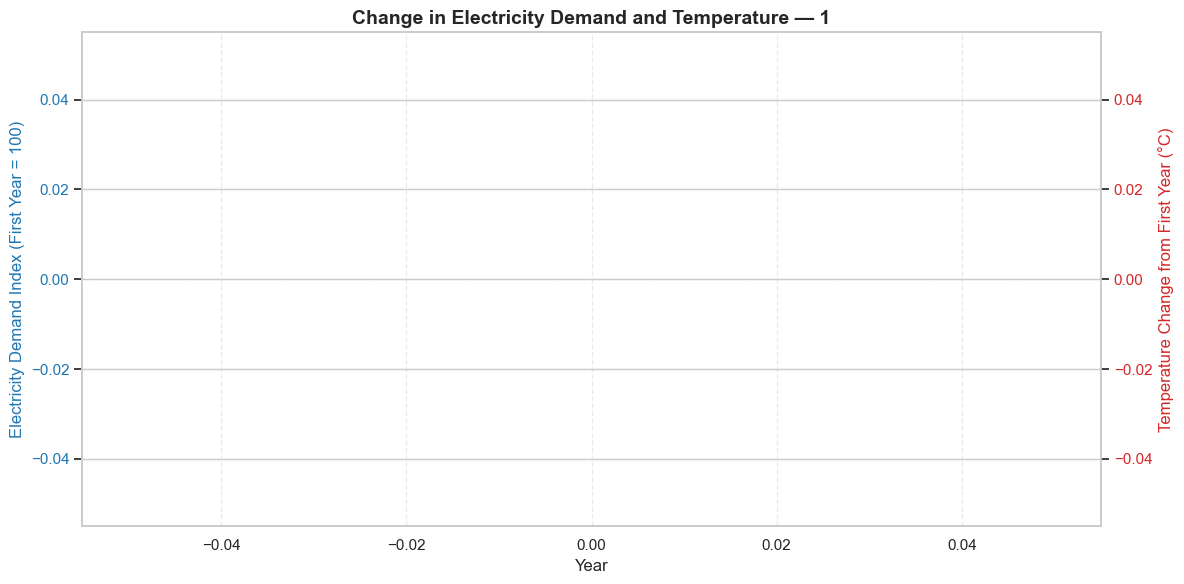

In [38]:
for region in region:

    region_data = annual[
        annual["REGION"] == region
    ].sort_values("year").copy()

    # 3-year rolling averages
    region_data["demand_smooth"] = (
        region_data["demand_index"]
        .rolling(window=3, center=True)
        .mean()
    )

    region_data["temp_smooth"] = (
        region_data["temp_change_from_first"]
        .rolling(window=3, center=True)
        .mean()
    )

    fig, ax1 = plt.subplots(figsize=(12, 6))

    # ==================================
    # Demand - original data
    # ==================================
    sns.lineplot(
        data=region_data,
        x="year",
        y="demand_index",
        color="tab:blue",
        alpha=0.3,
        linewidth=1,
        marker="o",
        ax=ax1
    )

    # Demand - smoothed trend
    sns.lineplot(
        data=region_data,
        x="year",
        y="demand_smooth",
        color="tab:blue",
        linewidth=3,
        ax=ax1
    )

    ax1.set_ylabel(
        "Electricity Demand Index (First Year = 100)",
        color="tab:blue"
    )

    ax1.tick_params(
        axis="y",
        labelcolor="tab:blue"
    )

    # ==================================
    # Temperature - second axis
    # ==================================
    ax2 = ax1.twinx()

    # Original temperature data
    sns.lineplot(
        data=region_data,
        x="year",
        y="temp_change_from_first",
        color="tab:red",
        alpha=0.3,
        linewidth=1,
        marker="s",
        ax=ax2
    )

    # Smoothed temperature trend
    sns.lineplot(
        data=region_data,
        x="year",
        y="temp_smooth",
        color="tab:red",
        linewidth=3,
        ax=ax2
    )

    ax2.set_ylabel(
        "Temperature Change from First Year (°C)",
        color="tab:red"
    )

    ax2.tick_params(
        axis="y",
        labelcolor="tab:red"
    )

    # ==================================
    # Graph styling
    # ==================================
    ax1.set_xlabel("Year")

    ax1.grid(
        True,
        linestyle="--",
        alpha=0.4
    )

    ax1.set_title(
        f"Change in Electricity Demand and Temperature — {region}",
        fontsize=14,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()

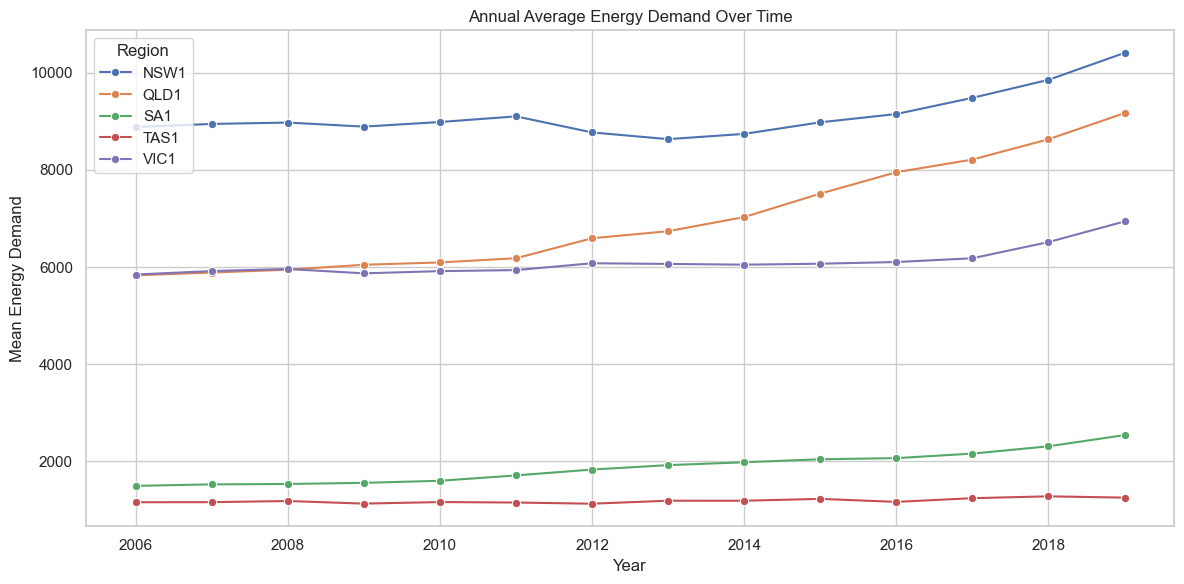

In [39]:
plt.figure(figsize=(12, 6))

pv_analysis['adjusted_demand'] = pv_analysis["mean_demand"] + pv_analysis['rooftop_pv_kw']/1000

sns.lineplot(
    data=pv_analysis,
    x="year",
    y="adjusted_demand",
    hue="REGION",
    marker="o"
)

plt.xlabel("Year")
plt.ylabel("Mean Energy Demand")
plt.title("Annual Average Energy Demand Over Time")
plt.legend(title="Region")
plt.tight_layout()
plt.show()

In [40]:
pv_analysis.head(5)

,REGION,year,mean_demand,max_demand,mean_temp,max_temp,min_temp,state,rooftop_pv_kw,adjusted_demand
6,NSW1,2006,8883.901099,13188.475,18.244746,44.0,5.8,NSW,1044.984,8884.946083
7,NSW1,2007,8944.314705,13812.310,18.452602,38.6,3.7,NSW,2309.109,8946.623814
8,NSW1,2008,8968.700636,14274.150,17.720978,34.7,5.3,NSW,6516.811,8975.217447
9,NSW1,2009,8865.705398,14106.440,18.570734,40.1,5.9,NSW,25706.473,8891.411871
10,NSW1,2010,8807.185635,13765.040,18.313636,41.2,4.4,NSW,179092.635,8986.278270


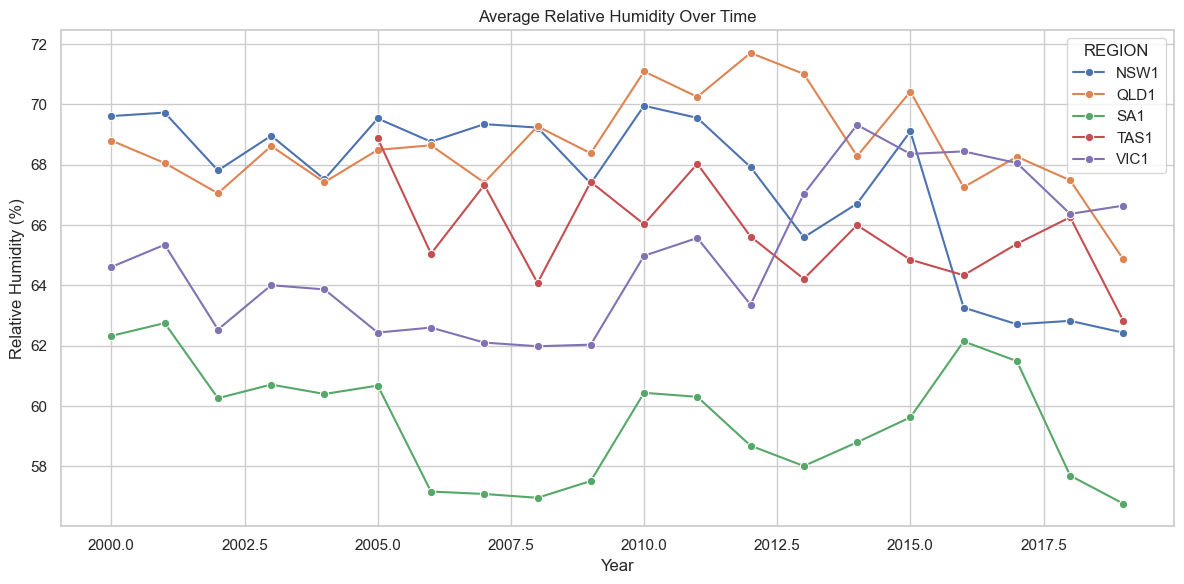

In [41]:
annual_humidity = (
    dfmonthly.groupby(["REGION", "year"])
    .agg(
        mean_humidity=("humidity_mean", "mean")
    )
    .reset_index()
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=annual_humidity,
    x="year",
    y="mean_humidity",
    hue="REGION",
    marker="o"
)

plt.title("Average Relative Humidity Over Time")
plt.xlabel("Year")
plt.ylabel("Relative Humidity (%)")

plt.tight_layout()
plt.show()

/var/folders/0q/t8srcths1tv0js49zb0h7wh80000gn/T/ipykernel_52816/1066753759.py:40: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
/opt/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


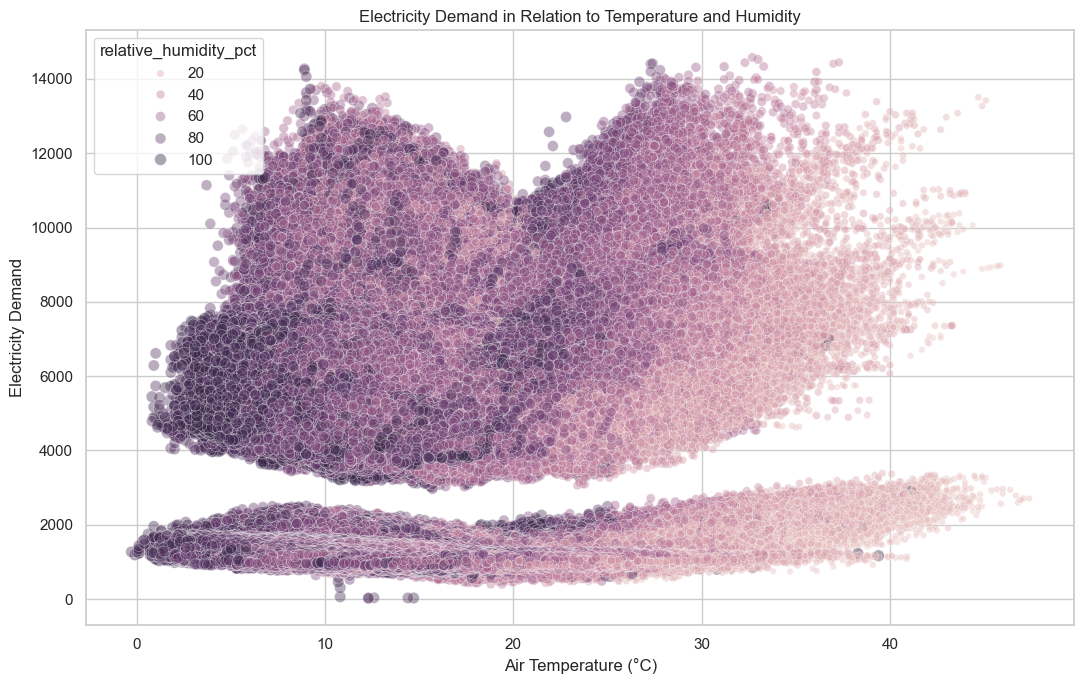

In [42]:
monthly["humidity_baseline"] = (
    monthly.groupby(["REGION", "month"])["humidity_mean"]
           .transform("mean")
)

monthly["humidity_anomaly"] = (
    monthly["humidity_mean"] -
    monthly["humidity_baseline"]
)

combined_humidity_anomaly = (
    monthly.groupby("date")
    .agg(
        mean_humidity_anomaly=(
            "humidity_anomaly",
            "mean"
        )
    )
    .reset_index()
)

plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=df,
    x="air_temperature_c",
    y="TOTALDEMAND",
    hue="relative_humidity_pct",
    size="relative_humidity_pct",
    alpha=0.4
)

plt.title(
    "Electricity Demand in Relation to Temperature and Humidity"
)

plt.xlabel("Air Temperature (°C)")
plt.ylabel("Electricity Demand")

plt.tight_layout()
plt.show()

/var/folders/0q/t8srcths1tv0js49zb0h7wh80000gn/T/ipykernel_52816/2875965705.py:29: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()


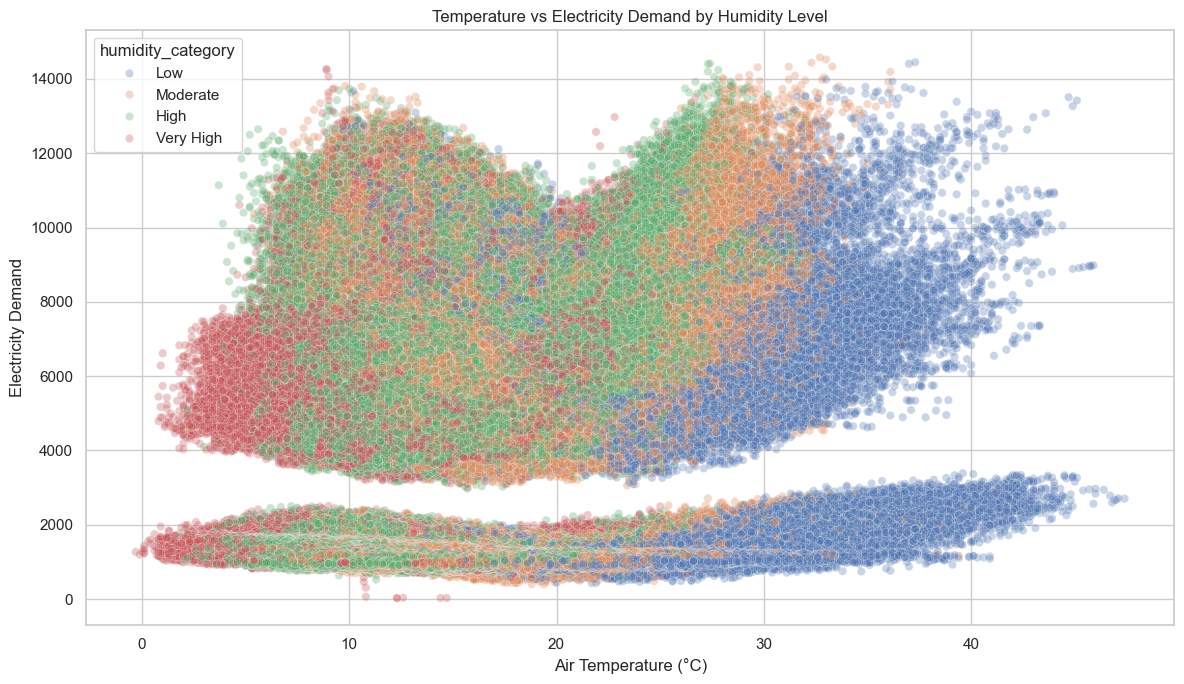

In [43]:
df["humidity_category"] = pd.cut(
    df["relative_humidity_pct"],
    bins=[0, 40, 60, 80, 100],
    labels=[
        "Low",
        "Moderate",
        "High",
        "Very High"
    ]
)

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=df,
    x="air_temperature_c",
    y="TOTALDEMAND",
    hue="humidity_category",
    alpha=0.3
)

plt.title(
    "Temperature vs Electricity Demand by Humidity Level"
)

plt.xlabel("Air Temperature (°C)")
plt.ylabel("Electricity Demand")

plt.tight_layout()
plt.show()

In [44]:
daily_plot = dfdaily.copy()

daily_plot["demand_normalised"] = (
    daily_plot.groupby("REGION")["demand_mean"]
    .transform(
        lambda x: (x - x.min()) / (x.max() - x.min())
    )
)

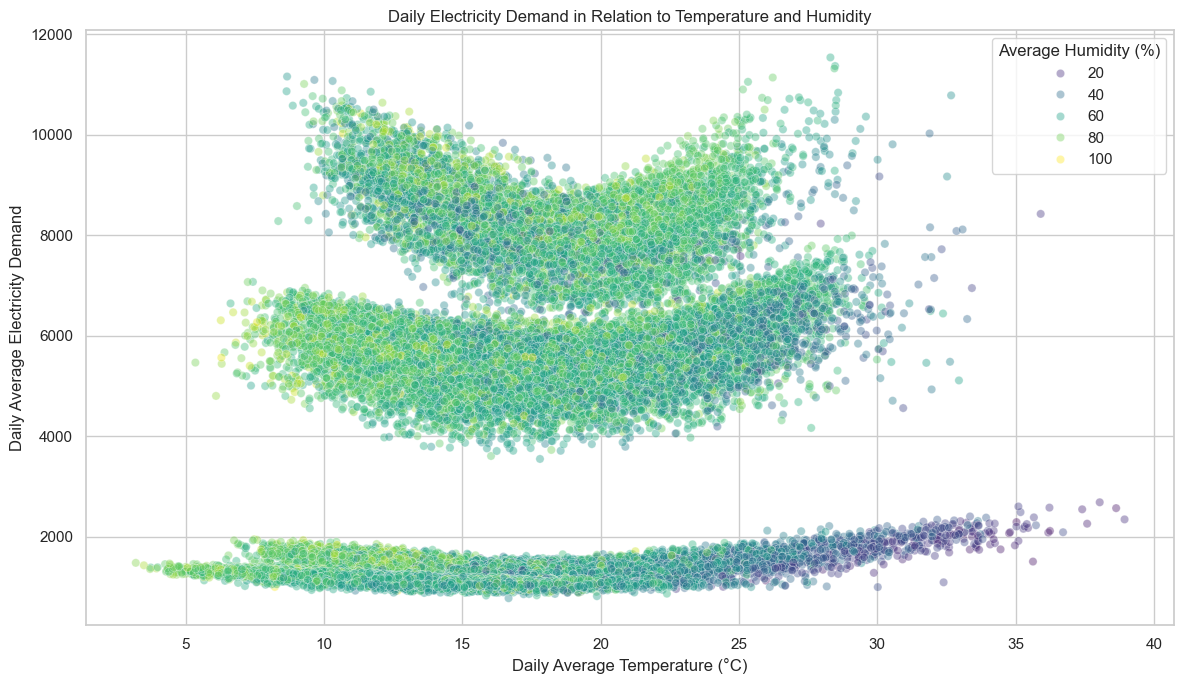

In [45]:
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=dfdaily,
    x="temp_mean",
    y="demand_mean",
    hue="humidity_mean",
    alpha=0.4,
    palette="viridis"
)

plt.title(
    "Daily Electricity Demand in Relation to Temperature and Humidity"
)

plt.xlabel("Daily Average Temperature (°C)")
plt.ylabel("Daily Average Electricity Demand")

plt.legend(
    title="Average Humidity (%)"
)

plt.tight_layout()
plt.show()

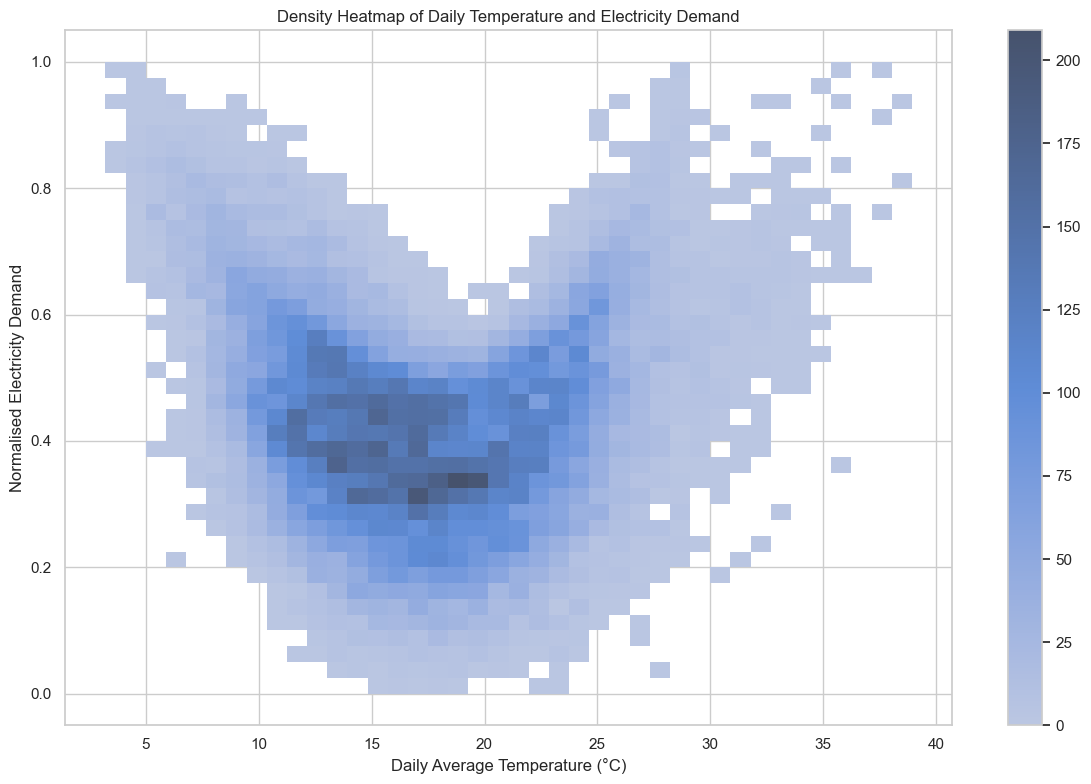

In [46]:
plt.figure(figsize=(12, 8))

sns.histplot(
    data=daily_plot,
    x="temp_mean",
    y="demand_normalised",
    bins=40,
    cbar=True
)

plt.title(
    "Density Heatmap of Daily Temperature and Electricity Demand"
)

plt.xlabel("Daily Average Temperature (°C)")
plt.ylabel("Normalised Electricity Demand")

plt.tight_layout()
plt.show()

In [47]:
R2 = 0.8173645239

In [48]:
print("Conclusions")
print(f"R2 Score = {R2}")

Conclusions
R2 Score = 0.8173645239


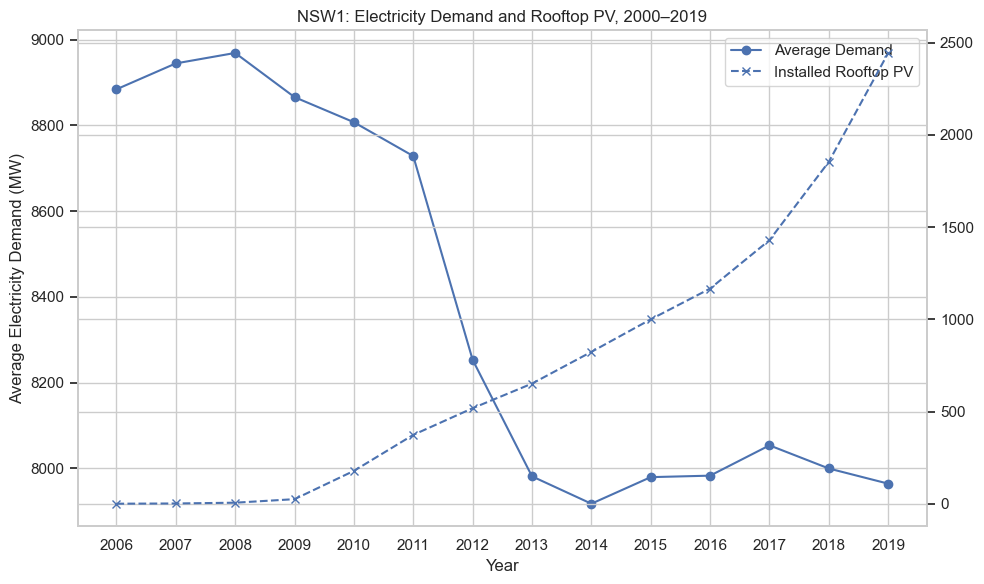

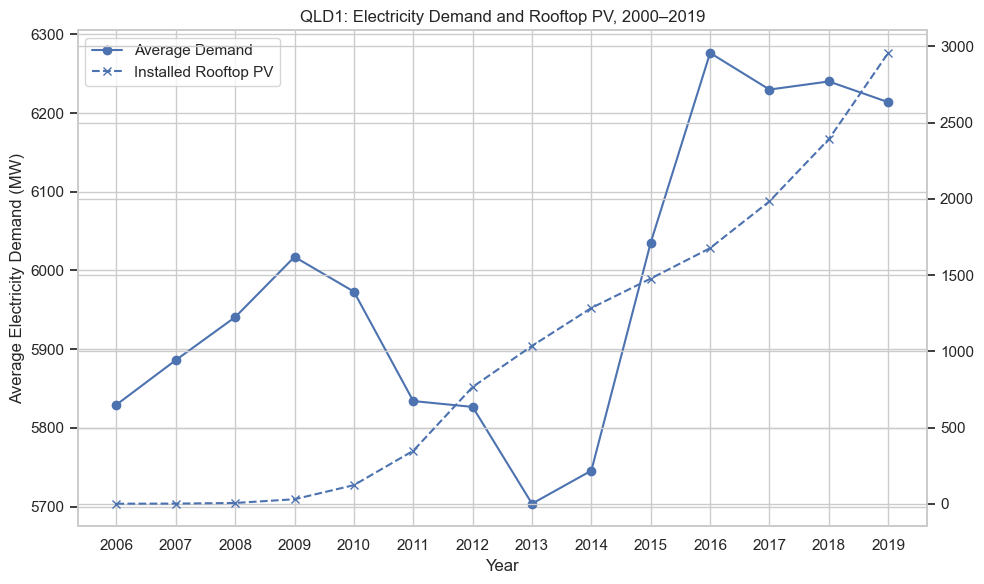

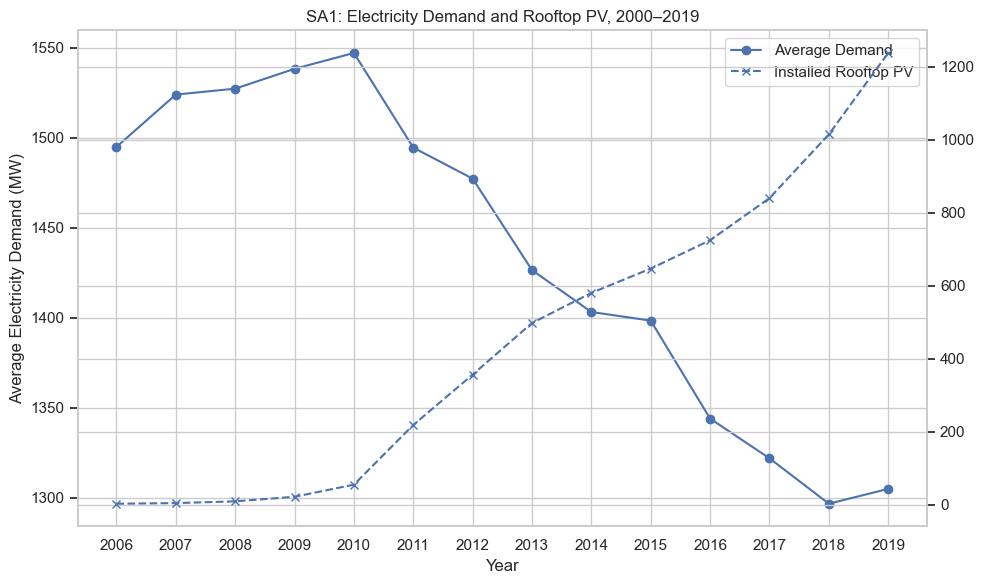

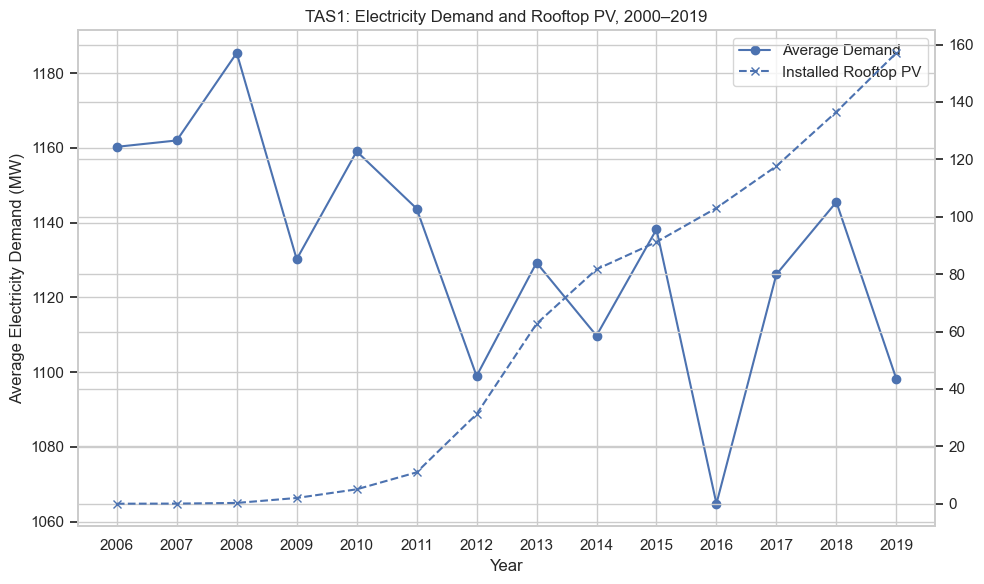

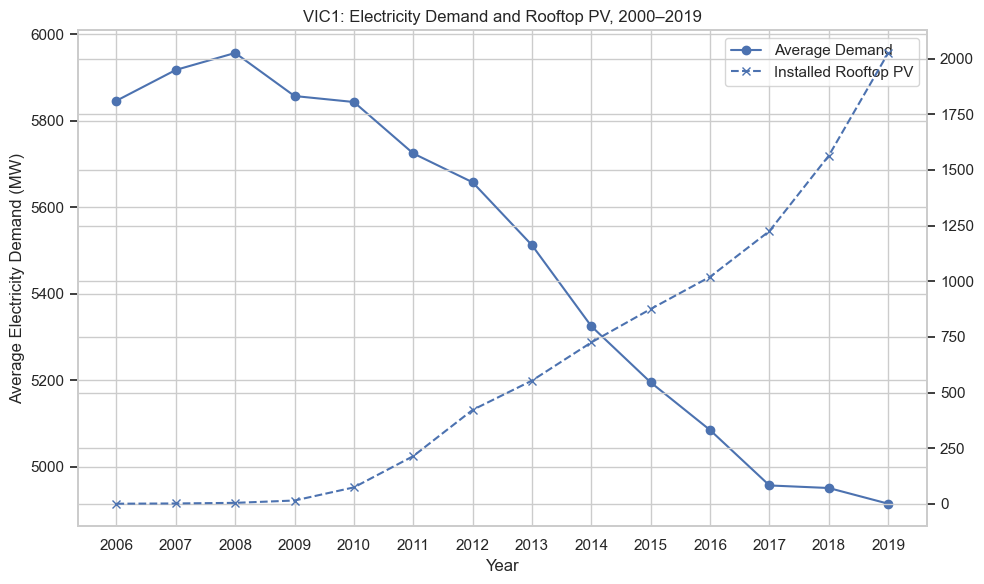

In [49]:
for region, data in pv_analysis.groupby("REGION"):

    fig, ax1 = plt.subplots(figsize=(10, 6))

    # Demand
    ax1.plot(
        data["year"],
        data["mean_demand"],
        marker="o",
        label="Average Demand"
    )

    ax1.set_xlabel("Year")
    ax1.set_ylabel("Average Electricity Demand (MW)")

    data["rooftop_pv_kw"] = data["rooftop_pv_kw"]/1000

    # PV
    ax2 = ax1.twinx()
    #ax2 = ax1.twiny()

    ax2.plot(
        data["year"],
        data["rooftop_pv_kw"],
        marker="x",
        linestyle="--",
        label="Installed Rooftop PV"
    )

    plt.title(
        f"{region}: Electricity Demand and Rooftop PV, 2000–2019"
    )

    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()

    ax1.legend(
        lines1 + lines2,
        labels1 + labels2,
        loc="best"
    )

    ax1.set_xticks(data["year"])
    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()

In [50]:
from sklearn.model_selection import RandomizedSearchCV, KFold
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [51]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(),
    "Lasso": Lasso(),
    "ElasticNet": ElasticNet(),
    "SVR": SVR(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42),
}

In [52]:
df["SETTLEMENTDATE"] = pd.to_datetime(df["SETTLEMENTDATE"])

df["hour_decimal"] = (
    df["SETTLEMENTDATE"].dt.hour
    + df["SETTLEMENTDATE"].dt.minute / 60
)

df["day_of_week"] = df["SETTLEMENTDATE"].dt.dayofweek

In [53]:
y = df["TOTALDEMAND"]

In [54]:
df["temperature_squared"] = df["air_temperature_c"] ** 2

In [55]:
df["SETTLEMENTDATE"] = pd.to_datetime(df["SETTLEMENTDATE"])

In [56]:
df["year"] = df["SETTLEMENTDATE"].dt.year
df["month"] = df["SETTLEMENTDATE"].dt.month
df["day_of_week"] = df["SETTLEMENTDATE"].dt.dayofweek

df["hour_decimal"] = (
    df["SETTLEMENTDATE"].dt.hour
    + df["SETTLEMENTDATE"].dt.minute / 60
)

In [57]:
categorical_features = [
    "REGION",
    "month",
    "day_of_week"
]

numeric_features = [
    "air_temperature_c",
    "temperature_squared",
    "wet_bulb_temp_c",
    "hour_decimal",
]

features = categorical_features + numeric_features
target = "TOTALDEMAND"

In [58]:
import pandas as pd
import numpy as np

from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures

from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [59]:
model_df = df[
    features + ["TOTALDEMAND", "SETTLEMENTDATE"]
].dropna().copy()

In [60]:
train = model_df[
    model_df["SETTLEMENTDATE"].dt.year <= 2015
]

test = model_df[
    model_df["SETTLEMENTDATE"].dt.year >= 2016
]

X_train = train[features]
y_train = train[target]

X_test = test[features]
y_test = test[target]

In [61]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numeric",
            StandardScaler(),
            numeric_features
        )
    ]
)

In [62]:
def evaluate_model(name, model, X_train, y_train, X_test, y_test):
    
    model.fit(X_train, y_train)
    
    y_pred = model.predict(X_test)
    
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    
    return {
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R²": r2
    }

In [63]:

linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

linear_results = evaluate_model(
    "Linear Regression",
    linear_model,
    X_train,
    y_train,
    X_test,
    y_test
)

In [64]:
from sklearn.linear_model import Ridge

ridge_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Ridge(alpha=1.0))
])

ridge_results = evaluate_model(
    "Ridge",
    ridge_model,
    X_train,
    y_train,
    X_test,
    y_test
)

In [65]:
from sklearn.linear_model import Lasso

lasso_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Lasso(
        alpha=0.01,
        max_iter=2000
    ))
])

lasso_results = evaluate_model(
    "Lasso",
    lasso_model,
    X_train,
    y_train,
    X_test,
    y_test
)

/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:656: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 8.349e+09, tolerance: 1.053e+09
  model = cd_fast.sparse_enet_coordinate_descent(


In [66]:
from sklearn.linear_model import ElasticNet

elastic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", ElasticNet(
        alpha=0.01,
        l1_ratio=0.5,
        max_iter=10000
    ))
])

elastic_results = evaluate_model(
    "Elastic Net",
    elastic_model,
    X_train,
    y_train,
    X_test,
    y_test
)

In [67]:
df_model = df.copy()

df_model["REGION_encoded"] = df_model["REGION"].astype("category").cat.codes

tree_features = [
    "REGION_encoded",
    "air_temperature_c",
    "temperature_squared",
    "wet_bulb_temp_c",
    "hour_decimal",
    "day_of_week",
    "month"
]

In [68]:
tree_preprocessor = ColumnTransformer(
    transformers=[
        (
            "region",
            OneHotEncoder(handle_unknown="ignore"),
            ["REGION"]
        ),
        (
            "numeric",
            "passthrough",
            [
                "air_temperature_c",
                "temperature_squared",
                "wet_bulb_temp_c",
                "hour_decimal",
                "day_of_week",
                "month"
            ]
        )
    ]
)

In [69]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline

tree_model = Pipeline([
    ("preprocessor", tree_preprocessor),
    ("model", DecisionTreeRegressor(
        max_depth=15,
        min_samples_split=10,
        random_state=42
    ))
])

tree_results = evaluate_model(
    "Decision Tree",
    tree_model,
    X_train,
    y_train,
    X_test,
    y_test
)

print(tree_results)

{'Model': 'Decision Tree', 'MAE': 426.6686542831303, 'RMSE': np.float64(588.0377933278199), 'R²': 0.9569331092321893}


In [70]:
rf_model = Pipeline([
    ("preprocessor", tree_preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        min_samples_split=10,
        random_state=42,
        n_jobs=-1
    ))
])

In [71]:
rf_results = evaluate_model(
    "Random Forest",
    rf_model,
    X_train,
    y_train,
    X_test,
    y_test
)

print(rf_results)

{'Model': 'Random Forest', 'MAE': 420.5080515943655, 'RMSE': np.float64(577.5951676112479), 'R²': 0.9584491279813645}


In [72]:
results = pd.DataFrame([
    linear_results,
    ridge_results,
    lasso_results,
    elastic_results,
    tree_results,
    rf_results
])

results

,Model,MAE,RMSE,R²
0,Linear Regression,604.944754,777.054236,0.924797
1,Ridge,604.946739,777.026809,0.924802
2,Lasso,604.935551,777.055784,0.924797
3,Elastic Net,607.442755,776.336233,0.924936
4,Decision Tree,426.668654,588.037793,0.956933
5,Random Forest,420.508052,577.595168,0.958449


In [73]:
def check_train_test(model, X_train, y_train, X_test, y_test):
    
    model.fit(X_train, y_train)
    
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    
    print("TRAINING")
    print("MAE:", mean_absolute_error(y_train, train_pred))
    print("RMSE:", np.sqrt(mean_squared_error(y_train, train_pred)))
    print("R²:", r2_score(y_train, train_pred))
    
    print("\nTEST")
    print("MAE:", mean_absolute_error(y_test, test_pred))
    print("RMSE:", np.sqrt(mean_squared_error(y_test, test_pred)))
    print("R²:", r2_score(y_test, test_pred))

In [74]:
check_train_test(
    tree_model,
    X_train,
    y_train,
    X_test,
    y_test
)

TRAINING
MAE: 245.7133236205398
RMSE: 362.2835646689419
R²: 0.9838196360749987

TEST
MAE: 426.6686542831303
RMSE: 588.0377933278199
R²: 0.9569331092321893


In [75]:
rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

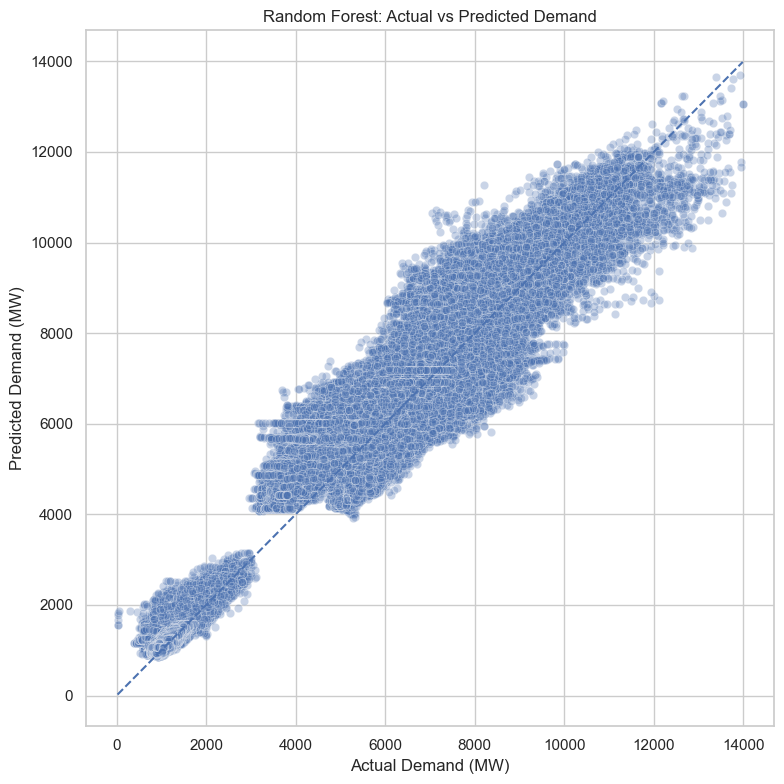

In [76]:
plt.figure(figsize=(8, 8))

sns.scatterplot(
    x=y_test,
    y=rf_pred,
    alpha=0.3
)

min_value = min(y_test.min(), rf_pred.min())
max_value = max(y_test.max(), rf_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Demand (MW)")
plt.ylabel("Predicted Demand (MW)")
plt.title("Random Forest: Actual vs Predicted Demand")

plt.tight_layout()
plt.show()

In [77]:
rf_model.fit(X_train, y_train)

feature_names = rf_model.named_steps[
    "preprocessor"
].get_feature_names_out()

importances = rf_model.named_steps[
    "model"
].feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values(
    "Importance",
    ascending=False
)

feature_importance

,Feature,Importance
0,region__REGION_NSW1,0.471759
3,region__REGION_TAS1,0.269881
2,region__REGION_SA1,0.180515
8,numeric__hour_decimal,0.047506
9,numeric__day_of_week,0.010348
6,numeric__temperature_squared,0.005883
5,numeric__air_temperature_c,0.005758
7,numeric__wet_bulb_temp_c,0.004099
10,numeric__month,0.003571
1,region__REGION_QLD1,0.000403


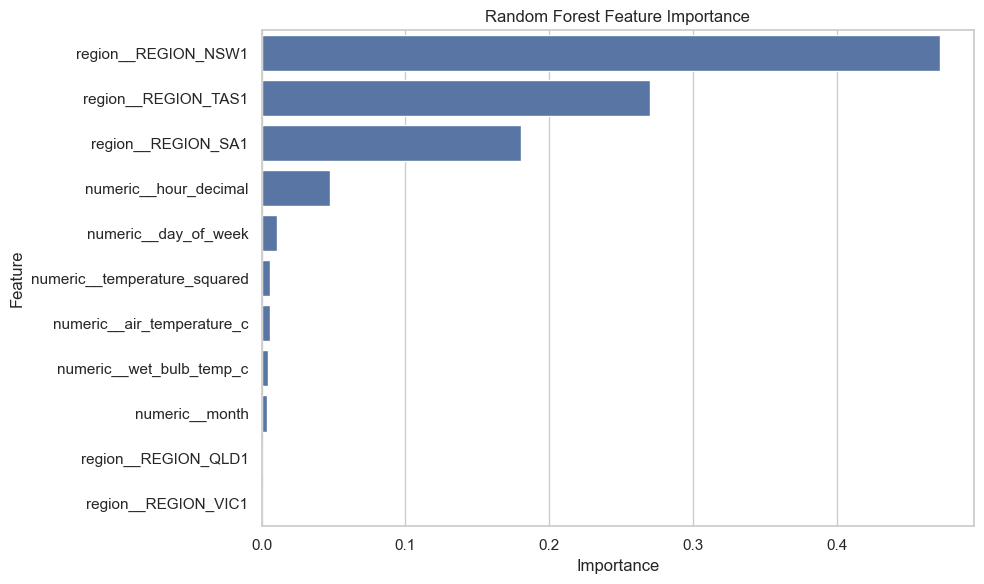

In [78]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [79]:
print("Train:")
print(train["SETTLEMENTDATE"].min())
print(train["SETTLEMENTDATE"].max())

print("\nTest:")
print(test["SETTLEMENTDATE"].min())
print(test["SETTLEMENTDATE"].max())

Train:
2000-01-01 00:30:00
2015-12-31 23:30:00

Test:
2016-01-01 00:00:00
2019-12-31 23:30:00


In [80]:
print("TRAIN PERIOD")
print(train["SETTLEMENTDATE"].min())
print(train["SETTLEMENTDATE"].max())

print("\nTEST PERIOD")
print(test["SETTLEMENTDATE"].min())
print(test["SETTLEMENTDATE"].max())

print("\nOVERLAPPING REGION + TIMESTAMP")
train_keys = set(
    zip(train["REGION"], train["SETTLEMENTDATE"])
)

test_keys = set(
    zip(test["REGION"], test["SETTLEMENTDATE"])
)

print(len(train_keys & test_keys))

print("\nDUPLICATE REGION + TIMESTAMP")
print(
    model_df.duplicated(
        ["REGION", "SETTLEMENTDATE"]
    ).sum()
)

print("\nMISSING VALUES")
print(model_df.isna().sum())

TRAIN PERIOD
2000-01-01 00:30:00
2015-12-31 23:30:00

TEST PERIOD
2016-01-01 00:00:00
2019-12-31 23:30:00

OVERLAPPING REGION + TIMESTAMP
0

DUPLICATE REGION + TIMESTAMP
2640

MISSING VALUES
REGION                 0
month                  0
day_of_week            0
air_temperature_c      0
temperature_squared    0
wet_bulb_temp_c        0
hour_decimal           0
TOTALDEMAND            0
SETTLEMENTDATE         0
dtype: int64


In [81]:
duplicates = model_df[
    model_df.duplicated(
        ["REGION", "SETTLEMENTDATE"],
        keep=False
    )
].sort_values(
    ["REGION", "SETTLEMENTDATE"]
)

duplicates.head(20)

,REGION,month,day_of_week,air_temperature_c,temperature_squared,wet_bulb_temp_c,hour_decimal,TOTALDEMAND,SETTLEMENTDATE
280888,NSW1,1,5,20.2,408.04,16.8,0.5,7702.93,2016-01-09 00:30:00
280889,NSW1,1,5,20.2,408.04,16.8,0.5,6989.08,2016-01-09 00:30:00
280890,NSW1,1,5,20.1,404.01,16.8,1.0,7588.75,2016-01-09 01:00:00
280891,NSW1,1,5,20.1,404.01,16.8,1.0,6723.30,2016-01-09 01:00:00
280892,NSW1,1,5,19.4,376.36,16.3,1.5,7386.97,2016-01-09 01:30:00
280893,NSW1,1,5,19.4,376.36,16.3,1.5,6450.35,2016-01-09 01:30:00
280894,NSW1,1,5,19.3,372.49,16.4,2.0,7137.67,2016-01-09 02:00:00
280895,NSW1,1,5,19.3,372.49,16.4,2.0,6209.19,2016-01-09 02:00:00
280896,NSW1,1,5,19.3,372.49,16.6,2.5,6773.95,2016-01-09 02:30:00
280897,NSW1,1,5,19.3,372.49,16.6,2.5,6007.83,2016-01-09 02:30:00


In [82]:
print("Number of duplicated rows:", len(duplicates))
print("Number of duplicated timestamps:",
      duplicates[["REGION", "SETTLEMENTDATE"]].drop_duplicates().shape[0])

Number of duplicated rows: 5280
Number of duplicated timestamps: 2640


In [83]:
duplicates.groupby("REGION").size()

REGION
NSW1    1056
QLD1    1056
SA1     1056
TAS1    1056
VIC1    1056
dtype: int64

In [84]:
daily = (
    df.groupby(["REGION", "date"])
      .agg(
          mean_demand=("TOTALDEMAND", "mean"),
          max_demand=("TOTALDEMAND", "max"),
          min_demand=("TOTALDEMAND", "min"),
          mean_temp=("air_temperature_c", "mean"),
          max_temp=("air_temperature_c", "max"),
          min_temp=("air_temperature_c", "min"),
          mean_wet_bulb=("wet_bulb_temp_c", "mean"),
          precipitation=("precipitation_9am_mm", "max")
      )
      .reset_index()
)

daily["date"] = pd.to_datetime(daily["date"])
daily["year"] = daily["date"].dt.year
daily["month"] = daily["date"].dt.month
daily["day_of_week"] = daily["date"].dt.dayofweek
'''
daily["HDD"] = np.maximum(18 - daily["mean_temp"], 0)

daily["CDD"] = np.maximum(daily["mean_temp"] - 18, 0)

base_temps = {
    "NSW1": 18,
    "VIC1": 18,
    "QLD1": 18,
    "SA1": 18,
    "TAS1": 18
}
'''
daily["year_index"] = daily["year"] - 2000
'''
daily["CDD_year"] = daily["CDD"] * daily["year_index"]
daily["HDD_year"] = daily["HDD"] * daily["year_index"]
'''


'\ndaily["CDD_year"] = daily["CDD"] * daily["year_index"]\ndaily["HDD_year"] = daily["HDD"] * daily["year_index"]\n'

In [85]:
daily

,REGION,date,mean_demand,max_demand,min_demand,mean_temp,max_temp,min_temp,mean_wet_bulb,precipitation,year,month,day_of_week,year_index
0,NSW1,2000-01-01,5720.094291,6763.57000,4650.29167,18.155319,20.8,14.8,14.585106,0.2,2000,1,5,0
1,NSW1,2000-01-02,5918.343333,6650.00333,4683.24667,17.979167,19.5,16.4,16.537500,18.8,2000,1,6,0
2,NSW1,2000-01-03,6234.452951,6936.19500,4820.81333,20.389583,23.3,16.4,17.710417,19.6,2000,1,0,0
3,NSW1,2000-01-04,7196.844653,8286.73500,5145.15000,24.879167,30.2,19.2,18.908333,0.2,2000,1,1,0
4,NSW1,2000-01-05,7076.017153,7932.49167,5328.70000,20.785417,24.9,17.3,14.414583,0.0,2000,1,2,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
34508,VIC1,2019-12-27,4469.002708,5777.97000,3654.65000,18.408333,22.3,13.8,15.541667,0.0,2019,12,4,19
34509,VIC1,2019-12-28,4730.070208,5797.25000,3822.50000,22.695833,28.0,19.3,18.137500,0.0,2019,12,5,19
34510,VIC1,2019-12-29,4928.896875,6555.02000,3798.54000,22.006250,26.5,17.1,19.058333,0.0,2019,12,6,19
34511,VIC1,2019-12-30,5850.421875,8204.01000,3993.96000,28.681250,40.6,19.1,19.827083,0.2,2019,12,0,19


In [93]:
# Features used by each regional model
numeric_features = ["mean_temp", "year_index"]
categorical_features = ["month", "day_of_week"]

features = numeric_features + categorical_features
target = "mean_demand"

# Store each fitted model and its results
regional_models = {}
results = []
warming_results = []

for region in sorted(daily["REGION"].dropna().unique()):

    # Select one region only
    region_df = daily[daily["REGION"] == region].copy()

    # Remove rows with missing modelling values
    region_df = region_df.dropna(
        subset=features + [target, "mean_temp", "year"]
    )

    # Chronological train/test split
    train = region_df[region_df["year"] <= 2015].copy()
    test = region_df[region_df["year"] >= 2016].copy()

    if train.empty or test.empty:
        print(f"Skipping {region}: insufficient train/test data")
        continue

    X_train = train[features]
    y_train = train[target]

    X_test = test[features]
    y_test = test[target]

    # Encode categorical features
    preprocessor = ColumnTransformer(
        transformers=[
            (
                "numeric",
                "passthrough",
                numeric_features
            ),
            (
                "categorical",
                OneHotEncoder(handle_unknown="ignore"),
                categorical_features
            )
        ]
    )

    rf = RandomForestRegressor(
        n_estimators=100,
        max_depth=215,
        min_samples_split=10,
        random_state=42,
        max_features=20,
        n_jobs=-1)
    # Create and train the model
    model = Pipeline([
        ("preprocessor", preprocessor),
        ("regression", rf)
    ])

    model.fit(X_train, y_train)

    # Predict demand for the held-out test period
    predictions = model.predict(X_test)

    # Evaluate model performance
    results.append({
        "Region": region,
        "Training days": len(train),
        "Testing days": len(test),
        "MAE (MW)": mean_absolute_error(y_test, predictions),
        "RMSE (MW)": np.sqrt(
            mean_squared_error(y_test, predictions)
        ),
        "R²": r2_score(y_test, predictions)
    })

# Display results
regional_results = pd.DataFrame(results).round(3)

print("MODEL PERFORMANCE BY REGION")
display(regional_results)


MODEL PERFORMANCE BY REGION


,Region,Training days,Testing days,MAE (MW),RMSE (MW),R²
0,NSW1,5842,1451,254.324,365.917,0.761
1,QLD1,5841,1451,242.737,303.596,0.606
2,SA1,5841,1451,108.367,136.651,0.600
3,TAS1,3876,1451,52.279,67.655,0.620
4,VIC1,5810,1451,296.562,378.072,0.559


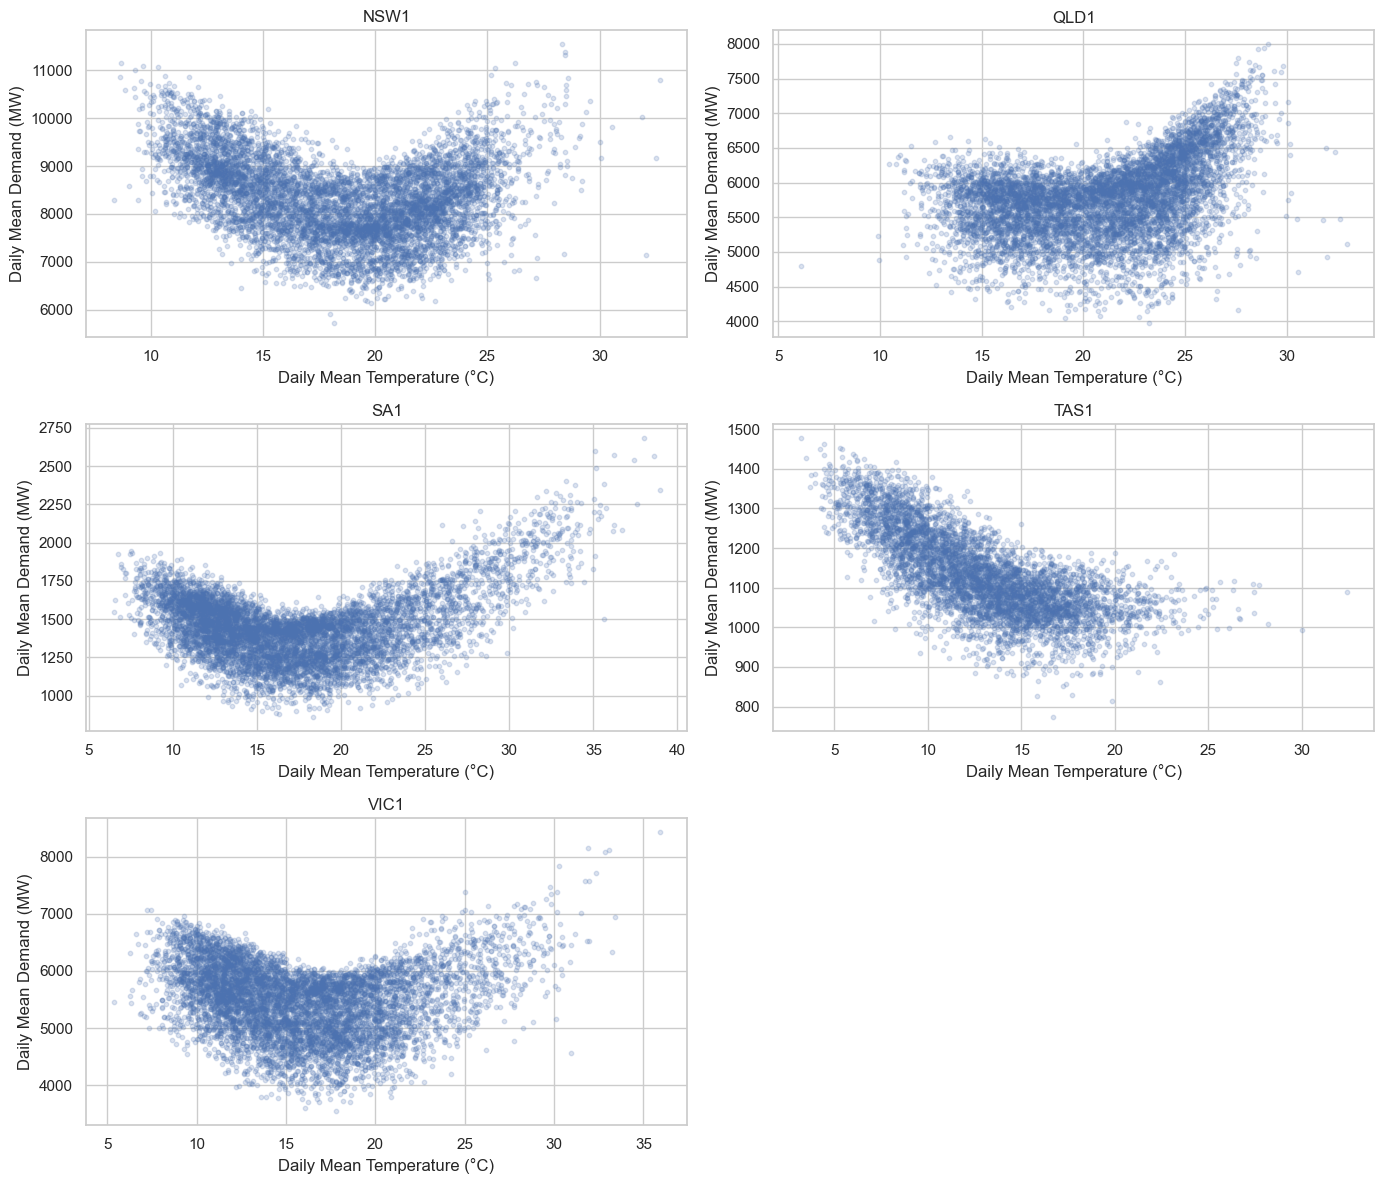

In [87]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 2, figsize=(14, 12))
axes = axes.flatten()

for i, region in enumerate(sorted(daily["REGION"].dropna().unique())):
    region_df = daily[daily["REGION"] == region]

    axes[i].scatter(
        region_df["mean_temp"],
        region_df["mean_demand"],
        alpha=0.2,
        s=10
    )

    axes[i].set_title(region)
    axes[i].set_xlabel("Daily Mean Temperature (°C)")
    axes[i].set_ylabel("Daily Mean Demand (MW)")

# Hide unused subplot if there are five regions
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

In [88]:
for name, score in zip(X_train.columns, rf.feature_importances_):
    print(name,np.round(score,3))

mean_temp 0.371
year_index 0.194
month 0.01
day_of_week 0.006


Adding more data to the model at the below code, results are kinda worse for everyone except NSW

In [89]:
import pandas as pd
import numpy as np

df["SETTLEMENTDATE"] = pd.to_datetime(df["SETTLEMENTDATE"])
df["date"] = df["SETTLEMENTDATE"].dt.normalize()

daily = (
    df.groupby(["REGION", "date"])
      .agg(
          mean_demand=("TOTALDEMAND", "mean"),
          peak_demand=("TOTALDEMAND", "max"),
          mean_temp=("air_temperature_c", "mean"),
          max_temp=("air_temperature_c", "max"),
          min_temp=("air_temperature_c", "min"),
          mean_wet_bulb=("wet_bulb_temp_c", "mean"),
          max_wet_bulb=("wet_bulb_temp_c", "max"),
          mean_precipitation=("precipitation_9am_mm", "mean"),
          mean_price=("RRP", "mean"),
          max_price=("RRP", "max"),
          mean_humidity=("relative_humidity_pct", "mean")
      )
      .reset_index()
)

daily["year"] = daily["date"].dt.year
daily["month"] = daily["date"].dt.month
daily["day_of_week"] = daily["date"].dt.dayofweek
daily["year_index"] = daily["year"] - daily["year"].min()

# Degree days using an initial 18°C threshold
daily["HDD"] = np.maximum(18 - daily["mean_temp"], 0)
daily["CDD"] = np.maximum(daily["mean_temp"] - 18, 0)

In [90]:
numeric_features = [
    "HDD",
    "CDD",
    "mean_temp",
    "mean_wet_bulb",
    "max_wet_bulb",
    "mean_precipitation",
    "year_index",
    "mean_humidity"
]

categorical_features = [
    "month",
    "day_of_week"
]

features = numeric_features + categorical_features
target = "mean_demand"


In [91]:
extended_numeric_features = numeric_features + [
    "mean_price",
    "max_price",
]

In [92]:
# Store each fitted model and its results
regional_models = {}
results = []
warming_results = []

for region in sorted(daily["REGION"].dropna().unique()):

    # Select one region only
    region_df = daily[daily["REGION"] == region].copy()

    # Remove rows with missing modelling values
    region_df = region_df.dropna(
        subset=features + [target, "mean_temp", "year"]
    )

    # Chronological train/test split
    train = region_df[region_df["year"] <= 2015].copy()
    test = region_df[region_df["year"] >= 2016].copy()

    if train.empty or test.empty:
        print(f"Skipping {region}: insufficient train/test data")
        continue

    X_train = train[features]
    y_train = train[target]

    X_test = test[features]
    y_test = test[target]

    # Encode categorical features
    preprocessor = ColumnTransformer(
        transformers=[
            (
                "numeric",
                "passthrough",
                numeric_features
            ),
            (
                "categorical",
                OneHotEncoder(handle_unknown="ignore"),
                categorical_features
            )
        ]
    )

    rf = RandomForestRegressor(
        n_estimators=100,
        max_depth=215,
        min_samples_split=10,
        random_state=42,
        n_jobs=-1)
    # Create and train the model
    model = Pipeline([
        ("preprocessor", preprocessor),
        ("regression", rf)
    ])

    model.fit(X_train, y_train)

    # Predict demand for the held-out test period
    predictions = model.predict(X_test)

    # Evaluate model performance
    results.append({
        "Region": region,
        "Training days": len(train),
        "Testing days": len(test),
        "MAE (MW)": mean_absolute_error(y_test, predictions),
        "RMSE (MW)": np.sqrt(
            mean_squared_error(y_test, predictions)
        ),
        "R²": r2_score(y_test, predictions)
    })

# Display results
regional_results = pd.DataFrame(results).round(3)

print("MODEL PERFORMANCE BY REGION")
display(regional_results)


MODEL PERFORMANCE BY REGION


,Region,Training days,Testing days,MAE (MW),RMSE (MW),R²
0,NSW1,5838,1451,237.255,333.345,0.802
1,QLD1,5838,1451,266.263,325.175,0.548
2,SA1,5838,1451,109.340,137.705,0.594
3,TAS1,3876,1449,51.130,66.026,0.639
4,VIC1,5809,1450,293.124,375.955,0.563
